# Example training and evaluation of LightGBM model

In [ ]:
import lightgbm, sklearn, matplotlib, seaborn

print("lightgbm:     ", lightgbm.__version__)
print("scikit-learn: ", sklearn.__version__)
print("matplotlib:   ", matplotlib.__version__)
print("seaborn:      ", seaborn.__version__)

lightgbm:      4.6.0
scikit-learn:  1.6.1
matplotlib:    3.10.0
seaborn:       0.13.2


In [ ]:
# import sys
# !{sys.executable} -m pip install cesnet-datazoo lightgbm scikit-learn matplotlib seaborn

!pip install cesnet-datazoo -q #  lightgbm scikit-learn matplotlib seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 444.8/444.8 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 51.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.12.1 requires pydantic<3.0.0,>=2.12.5, but you have pydantic 2.11.10 which is incompatible.
google-adk 2.7.1 requires pydantic<3,>=2.12, but you have pydantic 2.11.10 which is incompatible.


Download the CESNET-QUIC22 dataset if it is not already downloaded, enable logging, and set configuration.

In [ ]:
!pip install zenodo-get -q
!zenodo_get 10728760

INFO: Output directory: /content
INFO: Title: CESNET-QUIC22: A large one-month QUIC network traffic dataset from backbone lines
INFO: Total size: 21.0 GB
INFO: Number of files: 2
Files:   0% 0/2 [00:00<?, ?file/s]^C


In [ ]:
# под винду
# curl.exe -L -C - -o cesnet-quic22.zip "https://zenodo.org/records/10728760/files/cesnet-quic22.zip?download=1"

In [ ]:
# !wget https://liberouter.org/datazoo/download?bucket=cesnet-quic22&file=CESNET-QUIC22-XS.h5
# !wget -O cesnet-quic22.zip "https://zenodo.org/records/10728760/files/cesnet-quic22.zip?download=1"

!wget -O cesnet-tls22.zip "https://zenodo.org/records/10610895/files/cesnet-tls22.zip?download=1"

--2026-10-16 19:55:32--  https://zenodo.org/records/10610895/files/cesnet-tls22.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.51.60, 188.185.45.63, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9482192513 (8.8G) [application/octet-stream]
Saving to: ‘cesnet-tls22.zip’

cesnet-tls22.zip    100%[===================>]   8.83G  5.34MB/s    in 44m 22s 

2026-10-16 20:39:55 (3.40 MB/s) - ‘cesnet-tls22.zip’ saved [9482192513/9482192513]



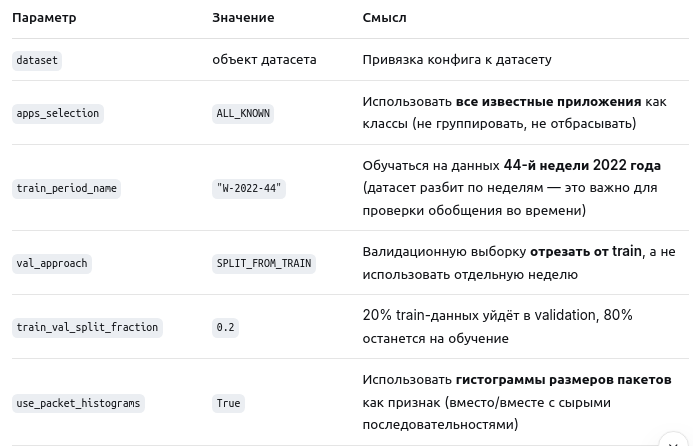

In [ ]:
import logging
from cesnet_datazoo.datasets import CESNET_QUIC22
# from cesnet_datazoo.datasets import CESNET_TLS22
from cesnet_datazoo.config import DatasetConfig, ValidationApproach, AppSelection

# Просто красиво форматирует сообщения в консоли: [время][модуль][уровень] - текст.
logging.basicConfig(
    level=logging.INFO,
    format="[%(asctime)s][%(name)s][%(levelname)s] - %(message)s")

dataset = CESNET_QUIC22(data_root="data/CESNET-QUIC22/", size="S") # XS, S, M, L
# dataset = CESNET_TLS22(data_root="data/CESNET-TLS22/", size="XS") # XS, S, M, L
common_params = {
    "dataset": dataset,
    "apps_selection": AppSelection.ALL_KNOWN,
    "train_period_name": "W-2022-44",
    "val_approach": ValidationApproach.SPLIT_FROM_TRAIN,
    "train_val_split_fraction": 0.2,
    "use_packet_histograms": True,
}
dataset_config = DatasetConfig(**common_params)
dataset.set_dataset_config_and_initialize(dataset_config)

The dataset hosting server is unreachable. Please contact us at https://github.com/CESNET/cesnet-datazoo/issues.


HTTPError: 503 Server Error: Service Unavailable for url: https://liberouter.org/datazoo/download?bucket=cesnet-quic22&file=CESNET-QUIC22-S.h5

Load training and validation dataframes and create LightGBM datasets.

In [ ]:
import lightgbm as lgb
from cesnet_datazoo.constants import APP_COLUMN

# возвращает список имён колонок-признаков, которые будут подаваться в модель.
# flatten_ppi=True — «flatten Packet Packet Interval / packet size histograms»: гистограммы размеров пакетов
# разворачиваются в плоский вектор (каждый бин становится отдельной колонкой).
# Без этого была бы вложенная структура, непригодная для LightGBM.
# Пример: ["PPI_0", "PPI_1", ..., "PPI_255"] — по одному значению на каждый размер пакета.
feature_names = dataset_config.get_feature_names(flatten_ppi=True)

# возвращает pandas.DataFrame с обучающими данными: строки = сессии/потоки трафика, колонки = признаки + метка APP_COLUMN.
train_df      = dataset.get_train_df(flatten_ppi=True)
val_df        = dataset.get_val_df(flatten_ppi=True)

# удаляет колонку APP из датафрейма, возвращает её как pandas.Series.
train_labels  = train_df.pop(APP_COLUMN)
val_labels    = val_df.pop(APP_COLUMN)

# lgb.Dataset — внутренний формат LightGBM, оптимизированный для обучения:
#     data — матрица признаков,
#     label — целевая переменная,
# feature_name — имена колонок (для важности признаков и читаемых логов).
# Сами данные пока не материализуются — LightGBM лениво построит бины при первом использовании в lgb.train(...).
lgb_train_dataset = lgb.Dataset(data=train_df, label=train_labels, feature_name=feature_names)
lgb_val_dataset   = lgb.Dataset(data=val_df,   label=val_labels, feature_name=feature_names)

print(f"Loaded {len(train_df)} train samples")
print(f"Loaded {len(val_df)} validation samples")

Loading data from dataloader


100%|██████████| 8162/8162 [00:04<00:00, 1948.02it/s]


Loading data from dataloader


100%|██████████| 192/192 [00:00<00:00, 237.50it/s]


Loaded 1566944 train samples
Loaded 391736 validation samples


Train the LightGBM model for 20 iterations.

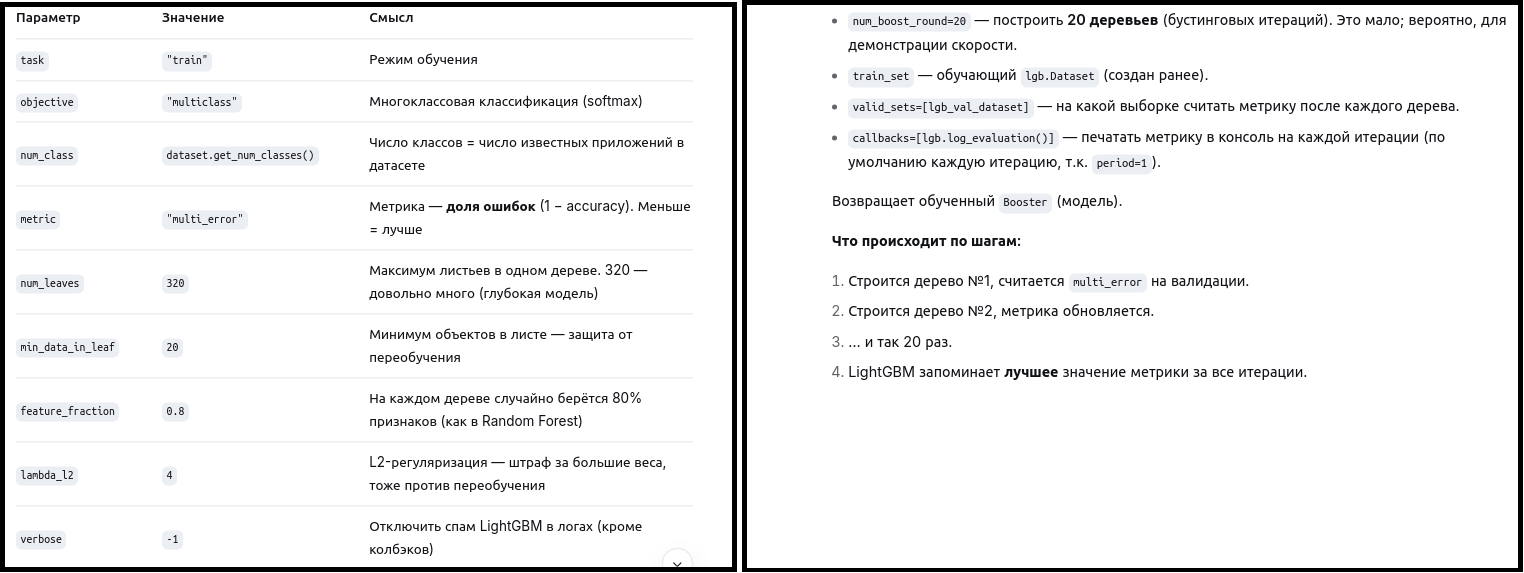

In [ ]:
lgb_params = {
    "task"            : "train",
    "objective"       : "multiclass",
    "num_class"       : dataset.get_num_classes(),
    "metric"          : "multi_error",
    "num_leaves"      : 320,
    "min_data_in_leaf": 20,
    "feature_fraction": 0.8,
    "lambda_l2"       : 4,
    "verbose"         : -1,
}

validation_metrics = {}
lgb_model = lgb.train(
    params          = lgb_params,
    num_boost_round = 20,
    train_set       = lgb_train_dataset,
    valid_sets      = [lgb_val_dataset],
    callbacks       = [lgb.log_evaluation()]
)
best_score = lgb_model.best_score["valid_0"]["multi_error"]
print(f"The best validation score is {best_score:.3f}")

[1]	valid_0's multi_error: 0.2201
[2]	valid_0's multi_error: 0.18671
[3]	valid_0's multi_error: 0.169668
[4]	valid_0's multi_error: 0.156833
[5]	valid_0's multi_error: 0.148156
[6]	valid_0's multi_error: 0.141858
[7]	valid_0's multi_error: 0.13591
[8]	valid_0's multi_error: 0.131326
[9]	valid_0's multi_error: 0.127297
[10]	valid_0's multi_error: 0.12366
[11]	valid_0's multi_error: 0.119966
[12]	valid_0's multi_error: 0.117048
[13]	valid_0's multi_error: 0.114202
[14]	valid_0's multi_error: 0.111922
[15]	valid_0's multi_error: 0.109793
[16]	valid_0's multi_error: 0.107687
[17]	valid_0's multi_error: 0.10574
[18]	valid_0's multi_error: 0.10394
[19]	valid_0's multi_error: 0.10223
[20]	valid_0's multi_error: 0.100693
The best validation score is 0.101


## Per-week evaluation

Training of the model was done on samples of the first (44th week of 2022) week of CESNET-QUIC22. Now, let's evaluate the model on the following three weeks (45th, 46th, and 47th).

For each week:

1. Create ``DatasetConfig`` and set the week as ``test_period_name``.
2. Load test dataframe.
3. Predict applications with the trained LightGBM model.
4. Compute classification accuracy.


Testing on period W-2022-45
Loading data from dataloader


100%|██████████| 1247/1247 [00:14<00:00, 85.99it/s] 


Loaded 2551901 test samples
Classification accuracy for W-2022-45 is 0.816

Testing on period W-2022-46
Loading data from dataloader


100%|██████████| 985/985 [00:13<00:00, 70.74it/s] 


Loaded 2016733 test samples
Classification accuracy for W-2022-46 is 0.722

Testing on period W-2022-47
Loading data from dataloader


100%|██████████| 1289/1289 [00:15<00:00, 84.98it/s] 


Loaded 2639441 test samples
Classification accuracy for W-2022-47 is 0.714


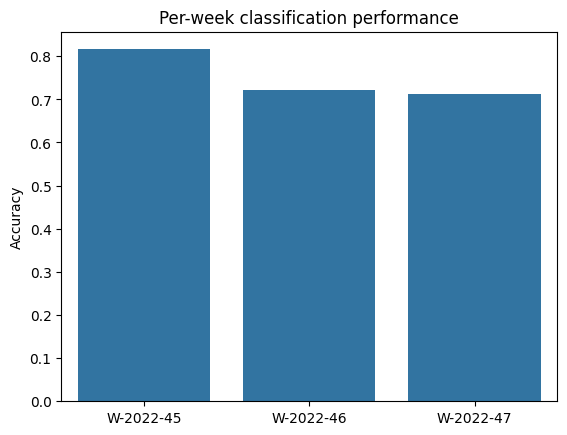

In [ ]:
from sklearn.metrics import accuracy_score
import seaborn

test_periods = ["W-2022-45", "W-2022-46", "W-2022-47"]
per_week_acc = []
for period in test_periods:
    print(f"\nTesting on period {period}")
    dataset_config = DatasetConfig(**common_params, test_period_name=period)
    dataset.set_dataset_config_and_initialize(dataset_config)
    test_df = dataset.get_test_df(flatten_ppi=True)
    print(f"Loaded {len(test_df)} test samples")
    true_labels = test_df.pop(APP_COLUMN)
    preds = lgb_model.predict(test_df).argmax(axis=1)
    acc = accuracy_score(true_labels, preds)
    per_week_acc.append(acc)
    print(f"Classification accuracy for {period} is {acc:.3f}")

seaborn.barplot(y=per_week_acc, x=test_periods).set(title="Per-week classification performance", ylabel="Accuracy");

## Per-day evaluation
Per-week evaluation might be too coarse-grained. Compute per-day performance. The big performance drop is related to a change of Google certificate and is discussed more in the *Encrypted traffic classification: the QUIC case* paper.

In [ ]:
test_dates = ["20221107", "20221108", "20221109", "20221110", "20221111", "20221112", "20221113",
              "20221114", "20221115", "20221116", "20221117", "20221118", "20221119", "20221120",
              "20221121", "20221122", "20221123", "20221124", "20221125", "20221126", "20221127"]
per_date_acc = []
for date in test_dates:
    dataset_config = DatasetConfig(**common_params, test_period_name=date)
    dataset.set_dataset_config_and_initialize(dataset_config)
    test_df = dataset.get_test_df(flatten_ppi=True)
    true_labels = test_df.pop(APP_COLUMN)
    preds = lgb_model.predict(test_df).argmax(axis=1)
    acc = accuracy_score(true_labels, preds)
    per_date_acc.append(acc)

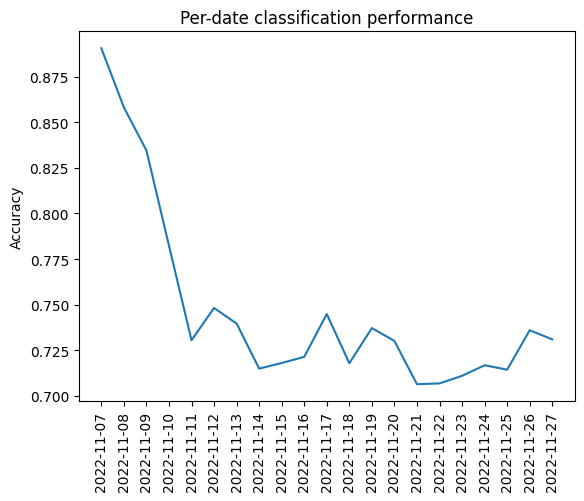

In [ ]:
from matplotlib import pyplot as plt

x_labels = list(map(lambda x: f"{x[:4]}-{x[4:6]}-{x[6:]}", test_dates))
fig, ax = plt.subplots()
seaborn.lineplot(x=range(len(per_date_acc)), y=per_date_acc, ax=ax)
ax.set_xticks(range(len(per_date_acc)))
ax.set_xticklabels(x_labels, rotation=90)
ax.set_ylabel("Accuracy")
ax.set(title="Per-date classification performance");

##XX

In [ ]:
# https://drive.google.com/file/d/1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i/view?usp=sharing

# import gdown
# gdown.download(id="1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i", output="cesnet\cesnat.zip", quiet=True)

!mkdir /content/cesnety
!gdown 1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i -O cesnet.zip
!unzip -qq /content/cesnet.zip -d /content/cesnet

mkdir: cannot create directory ‘/content/cesnet’: File exists
Downloading...
From (original): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i
From (redirected): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i&confirm=t&uuid=cfae3511-87f6-4035-b037-a87234c30fb4
To: /content/cesnet.zip
100% 1.84G/1.84G [00:37<00:00, 48.6MB/s]
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(1_Mon)-flows-20221031.csv.gz? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(1_Mon)-stats-20221031.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(2_Tue)-flows-20221101.csv.gz? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
y
replace /content/cesnet/(cesnet-quic22)-(W-2022-44)-(2_Tue)-stats-20221101.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: replace /content/cesnet/(cesnet-quic22)-README.md? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-fl

In [ ]:
import pandas as pd
df = pd.read_csv('/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz', nrows=1_000_000)
df.head(3)

,ID,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,...,FLAG_ACK,FLAG_ACK_REV,FLAG_PSH,FLAG_PSH_REV,FLAG_RST,FLAG_RST_REV,FLAG_SYN,FLAG_SYN_REV,FLAG_FIN,FLAG_FIN_REV
0,60052691,793,715,5,6,0.008550,"[[0, 1, 3, 0, 0], [1, -1, 1, -1, -1], [517, 21...",5,0.004,2,...,1,1,1,1,0,0,1,1,0,0
1,60052692,2386,4689,11,9,0.098527,"[[0, 5, 0, 0, 10, 36, 15, 16], [1, -1, -1, -1,...",8,0.082,2,...,1,1,1,1,0,0,1,1,1,1
2,60052693,1136,12840,9,16,0.112252,"[[0, 18, 0, 0, 0, 4, 1, 56, 0, 0, 0, 0, 0, 0, ...",15,0.079,2,...,1,1,1,1,0,0,1,1,1,1


In [ ]:
df.CATEGORY.value_counts().reset_index()

,CATEGORY,count
0,Analytics & Telemetry,126385
1,Other services and APIs,101861
2,Antivirus,99505
3,Streaming media,95240
4,File sharing,90211
5,Software updates,78208
6,Videoconferencing,67825
7,Social,51314
8,Authentication services,47953
9,Mail,45256


In [ ]:
df = df.drop('PPI', axis=1)
df = df.drop('CATEGORY', axis=1)
df.head(3)

,ID,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,APP,...,FLAG_ACK,FLAG_ACK_REV,FLAG_PSH,FLAG_PSH_REV,FLAG_RST,FLAG_RST_REV,FLAG_SYN,FLAG_SYN_REV,FLAG_FIN,FLAG_FIN_REV
0,60052691,793,715,5,6,0.008550,5,0.004,2,facebook-web,...,1,1,1,1,0,0,1,1,0,0
1,60052692,2386,4689,11,9,0.098527,8,0.082,2,bitdefender-nimbus,...,1,1,1,1,0,0,1,1,1,1
2,60052693,1136,12840,9,16,0.112252,15,0.079,2,google-www,...,1,1,1,1,0,0,1,1,1,1


In [ ]:
df.shape

(1000000, 28)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   ID              1000000 non-null  int64  
 1   BYTES           1000000 non-null  int64  
 2   BYTES_REV       1000000 non-null  int64  
 3   PACKETS         1000000 non-null  int64  
 4   PACKETS_REV     1000000 non-null  int64  
 5   DURATION        1000000 non-null  float64
 6   PPI_LEN         1000000 non-null  int64  
 7   PPI_DURATION    1000000 non-null  float64
 8   PPI_ROUNDTRIPS  1000000 non-null  int64  
 9   APP             1000000 non-null  object 
 10  TCP_FLAGS       1000000 non-null  int64  
 11  TCP_FLAGS_REV   1000000 non-null  int64  
 12  FLAG_CWR        1000000 non-null  int64  
 13  FLAG_CWR_REV    1000000 non-null  int64  
 14  FLAG_ECE        1000000 non-null  int64  
 15  FLAG_ECE_REV    1000000 non-null  int64  
 16  FLAG_URG        1000000 non-null  int

In [ ]:
df.PPI[2]

'[[0, 18, 0, 0, 0, 4, 1, 56, 0, 0, 0, 0, 0, 0, 0], [1, -1, -1, -1, -1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1], [517, 1430, 1430, 1430, 19, 80, 167, 1430, 592, 1430, 1430, 1430, 1228, 312, 27]]'

In [ ]:
df.APP[2]

'google-www'

In [ ]:
df.columns

Index(['ID', 'BYTES', 'BYTES_REV', 'PACKETS', 'PACKETS_REV', 'DURATION',
       'PPI_LEN', 'PPI_DURATION', 'PPI_ROUNDTRIPS', 'APP', 'TCP_FLAGS',
       'TCP_FLAGS_REV', 'FLAG_CWR', 'FLAG_CWR_REV', 'FLAG_ECE', 'FLAG_ECE_REV',
       'FLAG_URG', 'FLAG_URG_REV', 'FLAG_ACK', 'FLAG_ACK_REV', 'FLAG_PSH',
       'FLAG_PSH_REV', 'FLAG_RST', 'FLAG_RST_REV', 'FLAG_SYN', 'FLAG_SYN_REV',
       'FLAG_FIN', 'FLAG_FIN_REV'],
      dtype='object')

In [ ]:
df.APP.value_counts().reset_index()['count']
df_c = df.APP.value_counts().reset_index()
df_c = df_c[df_c['count']>1000]
df_c.tail(10)

,APP,count
117,the-weather-channel,1192
118,netflix,1191
119,booking-com,1185
120,gfe-events,1151
121,opera-speeddial,1139
122,firefox-settings,1138
123,apple-pancake,1134
124,ctu-idp2,1108
125,obalkyknih,1068
126,unity-games,1025


In [ ]:
df_c.shape[0]

127

In [ ]:
df_сut = df[ df.APP.isin(df_c.APP) ].reset_index(drop=True)
df_сut.shape

(975312, 28)

In [ ]:
df_сut["APP"] = df_сut["APP"].astype("category")

In [ ]:
df_сut.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 975312 entries, 0 to 975311
Data columns (total 28 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   ID              975312 non-null  int64   
 1   BYTES           975312 non-null  int64   
 2   BYTES_REV       975312 non-null  int64   
 3   PACKETS         975312 non-null  int64   
 4   PACKETS_REV     975312 non-null  int64   
 5   DURATION        975312 non-null  float64 
 6   PPI_LEN         975312 non-null  int64   
 7   PPI_DURATION    975312 non-null  float64 
 8   PPI_ROUNDTRIPS  975312 non-null  int64   
 9   APP             975312 non-null  category
 10  TCP_FLAGS       975312 non-null  int64   
 11  TCP_FLAGS_REV   975312 non-null  int64   
 12  FLAG_CWR        975312 non-null  int64   
 13  FLAG_CWR_REV    975312 non-null  int64   
 14  FLAG_ECE        975312 non-null  int64   
 15  FLAG_ECE_REV    975312 non-null  int64   
 16  FLAG_URG        975312 non-null  int64

In [ ]:
feature_names

['ID',
 'BYTES',
 'BYTES_REV',
 'PACKETS',
 'PACKETS_REV',
 'DURATION',
 'PPI_LEN',
 'PPI_DURATION',
 'PPI_ROUNDTRIPS',
 'TCP_FLAGS',
 'TCP_FLAGS_REV',
 'FLAG_CWR',
 'FLAG_CWR_REV',
 'FLAG_ECE',
 'FLAG_ECE_REV',
 'FLAG_URG',
 'FLAG_URG_REV',
 'FLAG_ACK',
 'FLAG_ACK_REV',
 'FLAG_PSH',
 'FLAG_PSH_REV',
 'FLAG_RST',
 'FLAG_RST_REV',
 'FLAG_SYN',
 'FLAG_SYN_REV',
 'FLAG_FIN',
 'FLAG_FIN_REV']

In [ ]:
train_df.head(3)

,ID,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,APP,...,FLAG_ACK,FLAG_ACK_REV,FLAG_PSH,FLAG_PSH_REV,FLAG_RST,FLAG_RST_REV,FLAG_SYN,FLAG_SYN_REV,FLAG_FIN,FLAG_FIN_REV
0,60409522,4245,4253,11,7,0.090961,10,0.045,3,rubiconproject,...,1,1,1,1,0,0,1,1,0,0
1,60894951,1862,1386,9,7,3.166204,5,0.081,2,google-www,...,1,1,1,1,0,0,1,1,1,1
2,60255679,4879,5620,13,11,1.021709,14,0.682,4,microsoft-diagnostic,...,1,1,1,1,0,0,1,1,1,1


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 780249 entries, 0 to 780248
Data columns (total 28 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   ID              780249 non-null  int64   
 1   BYTES           780249 non-null  int64   
 2   BYTES_REV       780249 non-null  int64   
 3   PACKETS         780249 non-null  int64   
 4   PACKETS_REV     780249 non-null  int64   
 5   DURATION        780249 non-null  float64 
 6   PPI_LEN         780249 non-null  int64   
 7   PPI_DURATION    780249 non-null  float64 
 8   PPI_ROUNDTRIPS  780249 non-null  int64   
 9   APP             780249 non-null  category
 10  TCP_FLAGS       780249 non-null  int64   
 11  TCP_FLAGS_REV   780249 non-null  int64   
 12  FLAG_CWR        780249 non-null  int64   
 13  FLAG_CWR_REV    780249 non-null  int64   
 14  FLAG_ECE        780249 non-null  int64   
 15  FLAG_ECE_REV    780249 non-null  int64   
 16  FLAG_URG        780249 non-null  int64

In [ ]:
a=1

In [ ]:
# https://drive.google.com/file/d/1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i/view?usp=sharing

# import gdown
# gdown.download(id="1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i", output="cesnet\cesnat.zip", quiet=True)

!mkdir /content/cesnety
!gdown 1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i -O cesnet.zip
!unzip -qq /content/cesnet.zip -d /content/cesnet

Downloading...
From (original): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i
From (redirected): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i&confirm=t&uuid=333004a1-c9de-487e-a31b-87b2c862dda3
To: /content/cesnet.zip
100% 1.84G/1.84G [00:23<00:00, 79.2MB/s]


In [ ]:
import pandas as pd
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1) Загрузка данных
# ---------------------------------------------------------------
df = pd.read_csv(
    '/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz',
    nrows=2_000_000,
)

df = df.drop('PPI', axis=1)
df = df.drop('CATEGORY', axis=1)

# ---------------------------------------------------------------
# 2) Фильтрация редких классов (>1000 примеров)
# ---------------------------------------------------------------
df_c = df.APP.value_counts().reset_index()
df_c = df_c[df_c['count'] > 1000]
df_cut = df[df.APP.isin(df_c.APP)].reset_index(drop=True)

print("Распределение классов после фильтрации:")
print(df_cut.APP.value_counts())

# ---------------------------------------------------------------
# 3) Признаки и метка
# ---------------------------------------------------------------
APP_COLUMN = "APP"

df_cut[APP_COLUMN] = df_cut[APP_COLUMN].astype("category")
app_categories = df_cut[APP_COLUMN].cat.categories
num_class = len(app_categories)

feature_names = [c for c in df_cut.columns if c != APP_COLUMN]

# ---------------------------------------------------------------
# 4) Train/val 80/20 со стратификацией
# ---------------------------------------------------------------
train_df, val_df = train_test_split(
    df_cut,
    test_size=0.2,
    random_state=42,
    stratify=df_cut[APP_COLUMN],
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

train_labels = train_df.pop(APP_COLUMN).cat.set_categories(app_categories).cat.codes
val_labels   = val_df.pop(APP_COLUMN).cat.set_categories(app_categories).cat.codes

train_df = train_df[feature_names]
val_df   = val_df[feature_names]

print(f"Loaded {len(train_df)} train samples")
print(f"Loaded {len(val_df)} validation samples")
print(f"Features ({len(feature_names)}): {feature_names}")
print(f"num_class: {num_class}")







Распределение классов после фильтрации:
APP
microsoft-update        119426
microsoft-diagnostic    103120
microsoft-settings       95390
outlook                  69325
skype                    63621
                         ...  
alza-cdn                  1287
opera-sitecheck           1268
cesnet-login              1256
adobe-cloud               1194
font-awesome              1015
Name: count, Length: 156, dtype: int64
Loaded 1589151 train samples
Loaded 397288 validation samples
Features (27): ['ID', 'BYTES', 'BYTES_REV', 'PACKETS', 'PACKETS_REV', 'DURATION', 'PPI_LEN', 'PPI_DURATION', 'PPI_ROUNDTRIPS', 'TCP_FLAGS', 'TCP_FLAGS_REV', 'FLAG_CWR', 'FLAG_CWR_REV', 'FLAG_ECE', 'FLAG_ECE_REV', 'FLAG_URG', 'FLAG_URG_REV', 'FLAG_ACK', 'FLAG_ACK_REV', 'FLAG_PSH', 'FLAG_PSH_REV', 'FLAG_RST', 'FLAG_RST_REV', 'FLAG_SYN', 'FLAG_SYN_REV', 'FLAG_FIN', 'FLAG_FIN_REV']
num_class: 156


In [3]:
# ---------------------------------------------------------------
# 5) Инициализация модели (Sklearn API)
# ---------------------------------------------------------------
lgb_model = LGBMClassifier(
    objective         = 'multiclass',
    num_class         = num_class,
    num_leaves        = 100,
    min_data_in_leaf  = 20,       # В sklearn API также работает как min_child_samples
    feature_fraction  = 0.8,      # Также работает как colsample_bytree
    lambda_l2         = 4,        # Также работает как reg_lambda
    n_estimators      = 200,      # Аналог num_boost_round
    n_jobs            = -1,       # Аналог num_threads (использовать все ядра)
    random_state      = 42,
    verbose           = -1        # Скрывает внутренние предупреждения
)


# ---------------------------------------------------------------
# 6) Обучение модели (Sklearn API)
# ---------------------------------------------------------------
lgb_model.fit(
    X           = train_df,
    y           = train_labels,
    eval_set    = [(train_df, train_labels), (val_df, val_labels)],
    eval_metric = 'multi_error',
    # eval_metric=['multi_error', 'multi_logloss'],
    callbacks   = [
        lgb.early_stopping(stopping_rounds=5),
        lgb.log_evaluation(period=1)
    ]
)

[1]	training's multi_error: 0.365347	training's multi_logloss: 2.18791	valid_1's multi_error: 0.3683	valid_1's multi_logloss: 2.21036
Training until validation scores don't improve for 5 rounds
[2]	training's multi_error: 0.297093	training's multi_logloss: 1.8088	valid_1's multi_error: 0.302257	valid_1's multi_logloss: 1.83961
[3]	training's multi_error: 0.265186	training's multi_logloss: 1.59291	valid_1's multi_error: 0.270658	valid_1's multi_logloss: 1.62847
[4]	training's multi_error: 0.247017	training's multi_logloss: 1.46829	valid_1's multi_error: 0.253061	valid_1's multi_logloss: 1.5067
[5]	training's multi_error: 0.23453	training's multi_logloss: 1.3555	valid_1's multi_error: 0.241304	valid_1's multi_logloss: 1.39582
[6]	training's multi_error: 0.225497	training's multi_logloss: 1.26184	valid_1's multi_error: 0.232567	valid_1's multi_logloss: 1.3034
[7]	training's multi_error: 0.21815	training's multi_logloss: 1.18504	valid_1's multi_error: 0.225617	valid_1's multi_logloss: 1.22

LGBMClassifier(feature_fraction=0.8, lambda_l2=2, min_data_in_leaf=20,
               n_estimators=200, n_jobs=-1, num_class=156, num_leaves=50,
               objective='multiclass', random_state=42, verbose=-1)

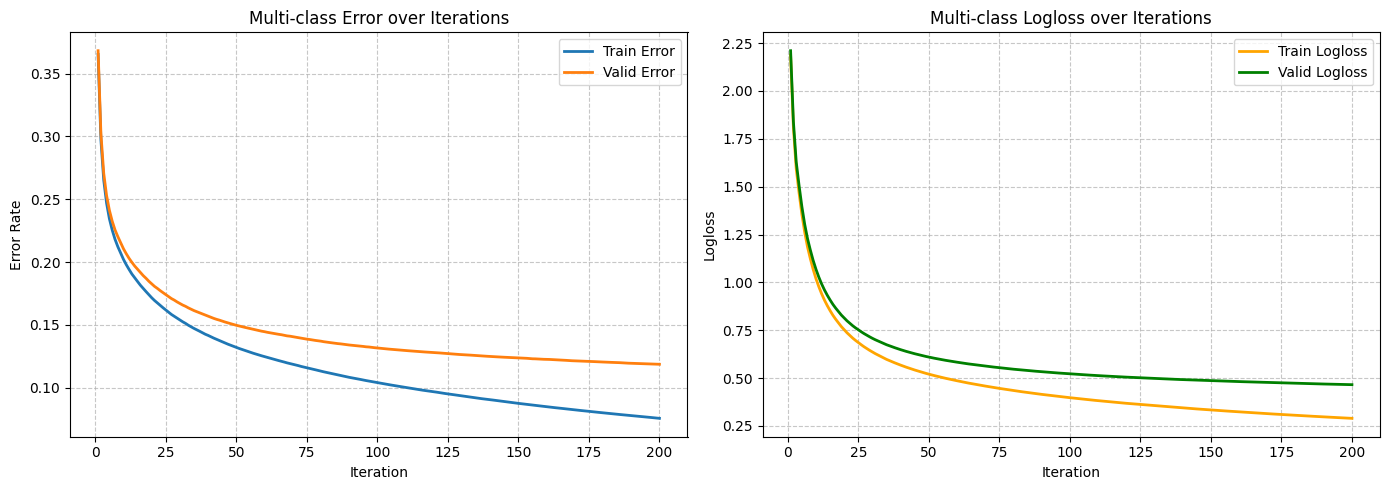


✅ Обучение завершено!
Лучшая итерация (Early Stopping): 200
Лучший validation multi_error: 0.119


In [4]:
# ---------------------------------------------------------------
# 7) Извлечение результатов и визуализация
# ---------------------------------------------------------------
history = lgb_model.evals_result_

# ИСПРАВЛЕНО: Ключи берутся из вашей структуры данных
train_key = 'training'  # <-- Было 'valid_0'
val_key = 'valid_1'     # <-- Осталось без изменений

iterations = range(1, len(history[train_key]['multi_error']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Error
ax1.plot(iterations, history[train_key]['multi_error'],
         label='Train Error', linewidth=2)
ax1.plot(iterations, history[val_key]['multi_error'],
         label='Valid Error', linewidth=2)
ax1.set_title('Multi-class Error over Iterations')
ax1.set_xlabel('Iteration')
ax1.set_ylabel('Error Rate')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

# График 2: Logloss
ax2.plot(iterations, history[train_key]['multi_logloss'],
         label='Train Logloss', linewidth=2, color='orange')
ax2.plot(iterations, history[val_key]['multi_logloss'],
         label='Valid Logloss', linewidth=2, color='green')
ax2.set_title('Multi-class Logloss over Iterations')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('Logloss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Получение лучшего результата
best_iter = lgb_model.best_iteration_
best_score = history[val_key]['multi_error'][best_iter - 1]

print(f"\n✅ Обучение завершено!")
print(f"Лучшая итерация (Early Stopping): {best_iter}")
print(f"Лучший validation multi_error: {best_score:.3f}")

In [5]:
import joblib
import numpy as np
from sklearn.metrics import accuracy_score, log_loss

# ---------------------------------------------------------------
# 1) Сохранение модели
# ---------------------------------------------------------------
model_filename = 'lgb_model.pkl'
joblib.dump(lgb_model, model_filename)
print(f"✅ Модель сохранена: {model_filename}")

✅ Модель сохранена: lgb_model.pkl


In [6]:
import pandas as pd
import joblib

# ---------------------------------------------------------------
# 1) Загрузка модели
# ---------------------------------------------------------------
model_filename = 'lgb_model.pkl'
loaded_model = joblib.load(model_filename)
print(f"✅ Модель загружена: {model_filename}")

# ---------------------------------------------------------------
# 2) ВОССТАНОВЛЕНИЕ списка классов из обучающего файла
# ---------------------------------------------------------------
# Загружаем ОРИГИНАЛЬНЫЙ обучающий файл (тот же, на котором учили модель)
df_train = pd.read_csv(
    '/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz',
    nrows=2_000_000  # ТО ЖЕ значение, что было при обучении!
)

# Повторяем ту же логику фильтрации, что была при обучении
df_train = df_train.drop('PPI', axis=1).drop('CATEGORY', axis=1)
df_c = df_train.APP.value_counts().reset_index()
df_c = df_c[df_c['count'] > 1000]

# Извлекаем список категорий в ТОМ ЖЕ порядке, что и при обучении
valid_app_names = (
    df_train[df_train.APP.isin(df_c.APP)]['APP']
    .astype("category")
    .cat.categories
    .tolist()
)

print(f"✅ Восстановлено {len(valid_app_names)} классов")
print(f"Примеры: {valid_app_names[:5]}")

# Теперь можно загружать новые данные и использовать valid_app_names для фильтрации

✅ Модель загружена: lgb_model.pkl
✅ Восстановлено 156 классов
Примеры: ['accuweather', 'adobe-ads', 'adobe-authentication', 'adobe-cloud', 'adobe-notifications']


In [7]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------------
# 0) Проверка, что все нужные переменные уже в памяти
# ---------------------------------------------------------------
# loaded_model - загружена ранее
# valid_app_names - восстановлена из обучающего файла ранее
# expected_features - возьмем из самой модели (она их помнит)

expected_features = loaded_model.feature_names_in_
print(f"✅ Модель ожидает {len(expected_features)} признаков.")
print(f"✅ В памяти {len(valid_app_names)} известных классов.")
print(f"   Примеры классов: {valid_app_names[:5]}")

# ---------------------------------------------------------------
# 1) Загрузка новых данных
# ---------------------------------------------------------------
df = pd.read_csv(
    '/content/cesnet/(cesnet-tls22)-(W-2021-40)-(7_Sun)-flows-20211010.csv.gz',
    nrows=10_000,  # Закомментируйте, чтобы проверить на всех данных
)

# Убираем колонки, которых не было при обучении
df = df.drop(columns=['PPI', 'CATEGORY'], errors='ignore')

APP_COLUMN = "APP"

# ---------------------------------------------------------------
# 2) ФИЛЬТРАЦИЯ: Оставляем ТОЛЬКО известные модели классы
# ---------------------------------------------------------------
total_before = len(df)

# Оставляем только строки, где APP есть в списке известных классов
df_filtered = df[df[APP_COLUMN].isin(valid_app_names)].reset_index(drop=True)

total_after = len(df_filtered)
dropped_count = total_before - total_after

print(f"\n📊 Статистика фильтрации:")
print(f"   Всего загружено строк:      {total_before}")
print(f"   Отброшено (новые классы):   {dropped_count}")
print(f"   Осталось для теста:         {total_after}")

if dropped_count > 0:
    unknown_classes = df[~df[APP_COLUMN].isin(valid_app_names)][APP_COLUMN].unique()
    print(f"   Обнаружены неизвестные классы: {list(unknown_classes[:10])}{'...' if len(unknown_classes) > 10 else ''}")

print("\nРаспределение известных классов в тестовых данных:")
print(df_filtered[APP_COLUMN].value_counts())

# ---------------------------------------------------------------
# 3) Формирование тестовой выборки (X и y)
# ---------------------------------------------------------------

# Признаки (X): берем строго те колонки, которые ожидает модель, в том же порядке
test_X = df_filtered[expected_features]

# Метки (y):
# 1. Делаем категориальным типом
# 2. ЖЕСТКО задаем порядок категорий (valid_app_names), чтобы код 0 всегда соответствовал одному и тому же классу
# 3. Извлекаем числовые коды (.cat.codes)
test_y = (
    df_filtered[APP_COLUMN]
    .astype("category")
    .cat.set_categories(valid_app_names)
    .cat.codes
)

# ---------------------------------------------------------------
# 4) Финальная проверка
# ---------------------------------------------------------------
print(f"\n✅ Тестовая выборка успешно сформирована!")
print(f"   Размер test_X: {test_X.shape}")
print(f"   Размер test_y: {test_y.shape}")
print(f"   Диапазон кодов в test_y: от {test_y.min()} до {test_y.max()} (должно быть 0..{len(valid_app_names)-1})")

# ---------------------------------------------------------------
# 5) Инференс (раскомментируйте, когда будете готовы)
# ---------------------------------------------------------------
# y_pred_proba = loaded_model.predict_proba(test_X)
# y_pred = np.argmax(y_pred_proba, axis=1)

✅ Модель ожидает 27 признаков.
✅ В памяти 156 известных классов.
   Примеры классов: ['accuweather', 'adobe-ads', 'adobe-authentication', 'adobe-cloud', 'adobe-notifications']

📊 Статистика фильтрации:
   Всего загружено строк:      10000
   Отброшено (новые классы):   69
   Осталось для теста:         9931
   Обнаружены неизвестные классы: ['gmail', 'ulozto', 'uzis-plf', 'datova-schranka', 'amazon-alexa', 'ctu-kos', '3dsecure', 'hicloud-connectivity', 'alza-logapi', 'aukro-backend']...

Распределение известных классов в тестовых данных:
APP
microsoft-update        508
microsoft-diagnostic    402
microsoft-settings      373
tiktok                  370
skype                   288
                       ... 
gitlab                    4
booking-com               3
alza-bnr                  2
sukl-erecept              1
mcafee-realprotect        1
Name: count, Length: 153, dtype: int64

✅ Тестовая выборка успешно сформирована!
   Размер test_X: (9931, 27)
   Размер test_y: (9931,)
   Диапа

In [ ]:
# import joblib

# # Сохраняем модель + метаданные в одном файле
# model_bundle = {
#     'model': lgb_model,
#     'classes': app_categories.tolist(),  # Текстовые названия классов
#     'features': feature_names,           # Список признаков
#     'num_class': num_class
# }

# joblib.dump(model_bundle, 'lgb_model_bundle.pkl')
# print("✅ Модель + метаданные сохранены в lgb_model_bundle.pkl")

#  #-----------------------------------------------------------------
#  bundle = joblib.load('lgb_model_bundle.pkl')
# loaded_model = bundle['model']
# valid_app_names = bundle['classes']  # Сразу есть!
# feature_names = bundle['features']   # И признаки тоже!

In [8]:
import numpy as np
import time
from sklearn.metrics import accuracy_score, log_loss
from tqdm import tqdm

print("\n" + "="*70)
print("⚡ МАКСИМАЛЬНО БЫСТРАЯ ПРОВЕРКА МОДЕЛИ (NumPy + Native Booster)")
print("="*70)

# ---------------------------------------------------------------
# 0) Подготовка данных для максимальной скорости (КРИТИЧЕСКИ ВАЖНО)
# ---------------------------------------------------------------
# Конвертируем в чистые NumPy массивы ОДИН РАЗ. Это убирает весь overhead Pandas.
X_np = test_X.values
y_true_np = test_y.values
class_names_np = np.array(valid_app_names)  # Мгновенный доступ по индексу

print(f"Данных: {len(X_np):,} строк, {X_np.shape[1]} признаков")
print(f"Используем нативный C++ Booster для ускорения...")

# ---------------------------------------------------------------
# 1) Быстрый инференс с прогресс-баром и батчингом
# ---------------------------------------------------------------
booster = loaded_model.booster_
# BATCH_SIZE = 500_000  # Оптимальный баланс между скоростью и потреблением RAM
BATCH_SIZE = 100_000  # Оптимальный баланс между скоростью и потреблением RAM
n_batches = int(np.ceil(len(X_np) / BATCH_SIZE))

all_proba = []
start_time = time.time()

for i in tqdm(range(n_batches), desc="Инференс", unit="batch"):
    start_idx = i * BATCH_SIZE
    end_idx = min((i + 1) * BATCH_SIZE, len(X_np))

    # Нативный predict работает напрямую с NumPy и выдает вероятности
    batch_proba = booster.predict(X_np[start_idx:end_idx])
    all_proba.append(batch_proba)

# Склеиваем результаты
y_pred_proba = np.vstack(all_proba)
y_pred = np.argmax(y_pred_proba, axis=1)

total_time = time.time() - start_time
print(f"\n✅ Инференс завершен за {total_time:.1f} сек. ({total_time/60:.1f} мин)")
print(f"   Скорость: {len(X_np)/total_time:,.0f} строк/сек")

# ---------------------------------------------------------------
# 2) Метрики качества (векторизированные, работают мгновенно)
# ---------------------------------------------------------------
accuracy = accuracy_score(y_true_np, y_pred)
error_rate = 1 - accuracy

# ИСПРАВЛЕНИЕ: явно указываем все 127 классов через параметр labels
# Это нужно, потому что в тестовой выборке могут быть представлены не все классы
logloss = log_loss(y_true_np, y_pred_proba, labels=np.arange(len(valid_app_names)))

print(f"\n📊 Метрики качества:")
print(f"   Accuracy:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"   Error Rate:   {error_rate:.4f} ({error_rate*100:.2f}%)")
print(f"   Log Loss:     {logloss:.4f}")

# ---------------------------------------------------------------
# 3) Примеры предсказаний (первые 10 объектов)
# ---------------------------------------------------------------
print(f"\n🔍 Примеры предсказаний (первые 10 объектов):")
print("-" * 70)

# Берем только первые 10 элементов из NumPy массивов (мгновенно)
for i in range(min(10, len(X_np))):
    true_idx = y_true_np[i]
    pred_idx = y_pred[i]
    pred_proba = y_pred_proba[i]

    true_class = class_names_np[true_idx]
    pred_class = class_names_np[pred_idx]

    # Топ-3 вероятности (argsort на 127 элементах занимает микросекунды)
    top_3_idx = np.argsort(pred_proba)[-3:][::-1]

    print(f"\nОбъект #{i+1}:")
    print(f"   Истинный класс:    {true_class}")
    print(f"   Предсказанный:     {pred_class} {'✅' if true_class == pred_class else '❌'}")
    print(f"   Топ-3 вероятности:")
    for j, idx in enumerate(top_3_idx, 1):
        cls = class_names_np[idx]
        prob = pred_proba[idx]
        marker = " ← предсказание" if idx == pred_idx else ""
        print(f"      {j}. {cls:20s}: {prob:.4f}{marker}")

# ---------------------------------------------------------------
# 4) Анализ уверенности (полностью векторизированный)
# ---------------------------------------------------------------
print("\n" + "="*70)
print("АНАЛИЗ УВЕРЕННОСТИ МОДЕЛИ")
print("="*70)

max_probas = np.max(y_pred_proba, axis=1)

print(f"\n📈 Статистика уверенности:")
print(f"   Средняя:     {np.mean(max_probas):.4f}")
print(f"   Медианная:   {np.median(max_probas):.4f}")
print(f"   Минимальная: {np.min(max_probas):.4f}")
print(f"   Максимальная:{np.max(max_probas):.4f}")

print(f"\n📊 Распределение уверенности:")
bins = [0, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0]
hist, _ = np.histogram(max_probas, bins=bins)
for i in range(len(hist)):
    pct = (hist[i] / len(max_probas)) * 100
    print(f"   {bins[i]:.2f}-{bins[i+1]:.2f}: {hist[i]:7d} объектов ({pct:5.2f}%)")

# ---------------------------------------------------------------
# 5) Правильные vs неправильные (векторизированные маски)
# ---------------------------------------------------------------
print("\n" + "="*70)
print("АНАЛИЗ ПРАВИЛЬНЫХ И НЕПРАВИЛЬНЫХ ПРЕДСКАЗАНИЙ")
print("="*70)

correct_mask = (y_pred == y_true_np)
incorrect_mask = ~correct_mask

n_correct = np.sum(correct_mask)
n_incorrect = np.sum(incorrect_mask)
total = len(y_true_np)

print(f"\n✅ Правильные: {n_correct:,} ({(n_correct/total)*100:.2f}%)")
print(f"   Средняя уверенность: {np.mean(max_probas[correct_mask]):.4f}")

print(f"\n❌ Неправильные: {n_incorrect:,} ({(n_incorrect/total)*100:.2f}%)")
print(f"   Средняя уверенность: {np.mean(max_probas[incorrect_mask]):.4f}")

# Уверенные, но неправильные (комбинированная маска, работает мгновенно)
if n_incorrect > 0:
    confident_wrong_mask = incorrect_mask & (max_probas > 0.8)
    confident_wrong_indices = np.where(confident_wrong_mask)[0]

    if len(confident_wrong_indices) > 0:
        print(f"\n⚠️  Уверенные ошибки (уверенность > 0.8): {len(confident_wrong_indices):,}")
        print("   Примеры (первые 5):")
        for idx in confident_wrong_indices[:5]:
            true_class = class_names_np[y_true_np[idx]]
            pred_class = class_names_np[y_pred[idx]]
            confidence = max_probas[idx]
            print(f"      {true_class:20s} → {pred_class:20s} (уверенность: {confidence:.4f})")

print("\n" + "="*70)
print("✅ ПРОВЕРКА ЗАВЕРШЕНА")
print("="*70)


⚡ МАКСИМАЛЬНО БЫСТРАЯ ПРОВЕРКА МОДЕЛИ (NumPy + Native Booster)
Данных: 9,931 строк, 27 признаков
Используем нативный C++ Booster для ускорения...


Инференс: 100%|██████████| 1/1 [01:01<00:00, 61.04s/batch]


✅ Инференс завершен за 61.1 сек. (1.0 мин)
   Скорость: 163 строк/сек

📊 Метрики качества:
   Accuracy:     0.8129 (81.29%)
   Error Rate:   0.1871 (18.71%)
   Log Loss:     0.7709

🔍 Примеры предсказаний (первые 10 объектов):
----------------------------------------------------------------------

Объект #1:
   Истинный класс:    teams
   Предсказанный:     teams ✅
   Топ-3 вероятности:
      1. teams               : 0.9584 ← предсказание
      2. grammarly           : 0.0098
      3. office-365          : 0.0079

Объект #2:
   Истинный класс:    microsoft-settings
   Предсказанный:     microsoft-settings ✅
   Топ-3 вероятности:
      1. microsoft-settings  : 0.9994 ← предсказание
      2. avast               : 0.0001
      3. office-365          : 0.0001

Объект #3:
   Истинный класс:    microsoft-update
   Предсказанный:     microsoft-update ✅
   Топ-3 вероятности:
      1. microsoft-update    : 0.9992 ← предсказание
      2. office-365          : 0.0003
      3. outlook            

In [ ]:
#
# медленно
#

from sklearn.metrics import accuracy_score, log_loss
import numpy as np

# ---------------------------------------------------------------
# 3) Проверка модели на ТЕСТОВЫХ данных (ОПТИМИЗИРОВАНО)
# ---------------------------------------------------------------
print("\n" + "="*70)
print("ПРОВЕРКА МОДЕЛИ НА ТЕСТОВЫХ ДАННЫХ")
print("="*70)

# ОДИН проход через модель
y_pred_proba = loaded_model.predict_proba(test_X)

# Argmax вручную (мгновенно)
y_pred = np.argmax(y_pred_proba, axis=1)

# Метрики
accuracy = accuracy_score(test_y, y_pred)
error_rate = 1 - accuracy
logloss = log_loss(test_y, y_pred_proba)

print(f"\n📊 Метрики качества:")
print(f"   Accuracy:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"   Error Rate:   {error_rate:.4f} ({error_rate*100:.2f}%)")
print(f"   Log Loss:     {logloss:.4f}")

# ---------------------------------------------------------------
# 4) Примеры предсказаний
# ---------------------------------------------------------------
print(f"\n🔍 Примеры предсказаний (первые 10 объектов):")
print("-" * 70)

# Используем восстановленный список классов
class_names = valid_app_names

for i in range(min(10, len(test_X))):
    true_class = class_names[test_y.iloc[i]]
    pred_class = class_names[y_pred[i]]
    pred_proba = y_pred_proba[i]

    # Топ-3 вероятности
    top_3_idx = np.argsort(pred_proba)[-3:][::-1]
    top_3_classes = [class_names[idx] for idx in top_3_idx]
    top_3_probs = [pred_proba[idx] for idx in top_3_idx]

    print(f"\nОбъект #{i+1}:")
    print(f"   Истинный класс:    {true_class}")
    print(f"   Предсказанный:     {pred_class} {'✅' if true_class == pred_class else '❌'}")
    print(f"   Топ-3 вероятности:")
    for j, (cls, prob) in enumerate(zip(top_3_classes, top_3_probs), 1):
        marker = " ← предсказание" if cls == pred_class else ""
        print(f"      {j}. {cls:20s}: {prob:.4f}{marker}")

# ---------------------------------------------------------------
# 5) Анализ уверенности
# ---------------------------------------------------------------
print("\n" + "="*70)
print("АНАЛИЗ УВЕРЕННОСТИ МОДЕЛИ")
print("="*70)

max_probas = np.max(y_pred_proba, axis=1)

print(f"\n📈 Статистика уверенности:")
print(f"   Средняя:     {np.mean(max_probas):.4f}")
print(f"   Медианная:   {np.median(max_probas):.4f}")
print(f"   Минимальная: {np.min(max_probas):.4f}")
print(f"   Максимальная:{np.max(max_probas):.4f}")

# Распределение уверенности
print(f"\n📊 Распределение уверенности:")
bins = [0, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0]
hist, _ = np.histogram(max_probas, bins=bins)
for i in range(len(hist)):
    print(f"   {bins[i]:.2f}-{bins[i+1]:.2f}: {hist[i]:5d} объектов ({hist[i]/len(max_probas)*100:5.2f}%)")

# ---------------------------------------------------------------
# 6) Правильные vs неправильные
# ---------------------------------------------------------------
print("\n" + "="*70)
print("АНАЛИЗ ПРАВИЛЬНЫХ И НЕПРАВИЛЬНЫХ ПРЕДСКАЗАНИЙ")
print("="*70)

correct_mask = (y_pred == test_y.values)
incorrect_mask = ~correct_mask

print(f"\n✅ Правильные: {np.sum(correct_mask)} ({np.sum(correct_mask)/len(test_y)*100:.2f}%)")
print(f"   Средняя уверенность: {np.mean(max_probas[correct_mask]):.4f}")

print(f"\n❌ Неправильные: {np.sum(incorrect_mask)} ({np.sum(incorrect_mask)/len(test_y)*100:.2f}%)")
print(f"   Средняя уверенность: {np.mean(max_probas[incorrect_mask]):.4f}")

# Уверенные, но неправильные
if np.sum(incorrect_mask) > 0:
    incorrect_indices = np.where(incorrect_mask)[0]
    confident_wrong = incorrect_indices[max_probas[incorrect_indices] > 0.8]

    if len(confident_wrong) > 0:
        print(f"\n⚠️  Уверенные ошибки (уверенность > 0.8): {len(confident_wrong)}")
        for idx in confident_wrong[:5]:
            true_class = class_names[test_y.iloc[idx]]
            pred_class = class_names[y_pred[idx]]
            confidence = max_probas[idx]
            print(f"      {true_class:20s} → {pred_class:20s} (уверенность: {confidence:.4f})")

print("\n" + "="*70)
print("✅ ПРОВЕРКА ЗАВЕРШЕНА")
print("="*70)


ПРОВЕРКА МОДЕЛИ НА ТЕСТОВЫХ ДАННЫХ


## Все заново


In [1]:
def print_aligned_dict(data, indent=0, decimals=2):
    """Красивый вывод словаря с авто-округлением чисел"""
    if not data:
        return

    max_key_len = max(len(str(key)) for key in data.keys())
    indent_str = ' ' * indent

    for key, value in data.items():
        key_str = str(key)
        padding = ' ' * (max_key_len - len(key_str))

        # Определяем тип значения
        if value is None:
            val_str = "null"
        elif isinstance(value, bool):  # работает и с np.bool_
            val_str = "true" if value else "false"
        elif isinstance(value, str):
            val_str = f'"{value}"'
        elif isinstance(value, (int, np.integer)):
            val_str = str(value)
        elif isinstance(value, (float, np.floating)):
            val_str = f"{value:.{decimals}f}"
        elif isinstance(value, np.ndarray):
            if value.size == 0:
                val_str = "[]"
            elif np.issubdtype(value.dtype, np.floating):
                rounded = [f"{x:.{decimals}f}" for x in value]
                val_str = f"[{', '.join(rounded)}]"
            else:
                val_str = str(value.tolist())
        elif isinstance(value, (list, tuple)):
            if all(isinstance(x, (float, np.floating)) for x in value):
                rounded = [f"{x:.{decimals}f}" for x in value]
                val_str = f"[{', '.join(rounded)}]"
            else:
                val_str = str(value)
        elif isinstance(value, dict):
            print(f'{indent_str}{padding}{key_str}:')
            print_aligned_dict(value, indent + 2, decimals)
            continue
        else:
            val_str = str(value)

        print(f'{indent_str}{padding}{key_str}: {val_str}')

In [2]:
!mkdir /content/cesnety
!gdown 1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i -O cesnet.zip
!unzip -qq /content/cesnet.zip -d /content/cesnet

Downloading...
From (original): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i
From (redirected): https://drive.google.com/uc?id=1IG-omP_l7bRfl62nr8EIQ5LP7doi8h9i&confirm=t&uuid=6ff5ecf1-ef6c-470b-bea8-0e3972f08a43
To: /content/cesnet.zip
100% 1.84G/1.84G [00:24<00:00, 75.2MB/s]


In [3]:
import pandas as pd
# df = pd.read_csv('/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz', nrows=1_000_000)
df = pd.read_csv('/content/cesnet/(cesnet-tls22)-(W-2021-40)-(6_Sat)-flows-20211009.csv.gz', nrows=100_000)
df["APP"] = df["APP"].astype("category")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 30 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   ID              100000 non-null  int64   
 1   BYTES           100000 non-null  int64   
 2   BYTES_REV       100000 non-null  int64   
 3   PACKETS         100000 non-null  int64   
 4   PACKETS_REV     100000 non-null  int64   
 5   DURATION        100000 non-null  float64 
 6   PPI             100000 non-null  object  
 7   PPI_LEN         100000 non-null  int64   
 8   PPI_DURATION    100000 non-null  float64 
 9   PPI_ROUNDTRIPS  100000 non-null  int64   
 10  APP             100000 non-null  category
 11  CATEGORY        100000 non-null  object  
 12  TCP_FLAGS       100000 non-null  int64   
 13  TCP_FLAGS_REV   100000 non-null  int64   
 14  FLAG_CWR        100000 non-null  int64   
 15  FLAG_CWR_REV    100000 non-null  int64   
 16  FLAG_ECE        100000 non-null  int64 

In [28]:
df.TCP_FLAGS[:5]

,TCP_FLAGS
0,26
1,27
2,27
3,26
4,27


In [10]:
df.CATEGORY[:5]

,CATEGORY
0,Social
1,Antivirus
2,Search
3,File sharing
4,Software updates


In [4]:
# df = df.drop(['ID', 'PPI', 'CATEGORY', 'TCP_FLAGS', 'TCP_FLAGS_REV'], axis=1)
df = df.drop(['ID', 'PPI', 'CATEGORY'], axis=1)
df.head()

,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,APP,TCP_FLAGS,...,FLAG_ACK,FLAG_ACK_REV,FLAG_PSH,FLAG_PSH_REV,FLAG_RST,FLAG_RST_REV,FLAG_SYN,FLAG_SYN_REV,FLAG_FIN,FLAG_FIN_REV
0,793,715,5,6,0.008550,5,0.004,2,facebook-web,26,...,1,1,1,1,0,0,1,1,0,0
1,2386,4689,11,9,0.098527,8,0.082,2,bitdefender-nimbus,27,...,1,1,1,1,0,0,1,1,1,1
2,1136,12840,9,16,0.112252,15,0.079,2,google-www,27,...,1,1,1,1,0,0,1,1,1,1
3,3430,540,7,8,0.442061,7,0.228,2,dropbox,26,...,1,1,1,1,0,0,1,1,0,0
4,1170,3548,12,9,0.159959,11,0.090,3,microsoft-update,27,...,1,1,1,1,0,0,1,1,1,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   BYTES           100000 non-null  int64   
 1   BYTES_REV       100000 non-null  int64   
 2   PACKETS         100000 non-null  int64   
 3   PACKETS_REV     100000 non-null  int64   
 4   DURATION        100000 non-null  float64 
 5   PPI_LEN         100000 non-null  int64   
 6   PPI_DURATION    100000 non-null  float64 
 7   PPI_ROUNDTRIPS  100000 non-null  int64   
 8   APP             100000 non-null  category
 9   FLAG_CWR        100000 non-null  int64   
 10  FLAG_CWR_REV    100000 non-null  int64   
 11  FLAG_ECE        100000 non-null  int64   
 12  FLAG_ECE_REV    100000 non-null  int64   
 13  FLAG_URG        100000 non-null  int64   
 14  FLAG_URG_REV    100000 non-null  int64   
 15  FLAG_ACK        100000 non-null  int64   
 16  FLAG_ACK_REV    100000 non-null  int64 

In [52]:
df.isna().mean()

,0
ID,0.0
BYTES,0.0
BYTES_REV,0.0
PACKETS,0.0
PACKETS_REV,0.0
DURATION,0.0
PPI_LEN,0.0
PPI_DURATION,0.0
PPI_ROUNDTRIPS,0.0
APP,0.0


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# ---------- 1. Матрица корреляций только по числовым признакам ----------

def correlation_matrix(
    df: pd.DataFrame,
    columns: list[str],
    threshold: float = 0.8,
    method: str = "spearman",
    figsize: tuple = (10, 8),          # ← было (14, 12)
):
    missing = [c for c in columns if c not in df.columns]
    if missing:
        raise ValueError(f"Нет колонок: {missing}")

    sub = df[columns].select_dtypes(include="number")
    skipped = set(columns) - set(sub.columns)
    if skipped:
        print(f"⚠ Пропущены нечисловые: {skipped}")

    corr = sub.corr(method=method)

    fig, ax = plt.subplots(figsize=figsize)
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(
        corr, mask=mask,
        annot=True, fmt=".2f",
        annot_kws={"size": 7},        # ← размер цифр в ячейках
        cmap="coolwarm", center=0, vmin=-1, vmax=1,
        square=True,
        linewidths=0.3,               # ← тоньше линии между ячейками
        cbar_kws={"shrink": 0.7},     # ← короче colorbar
        ax=ax,
    )
    ax.set_title(f"Корреляционная матрица ({method})", fontsize=9)
    ax.tick_params(axis="both", labelsize=8)   # ← подписи осей мельче
    plt.tight_layout()
    plt.show()

    # пары выше порога
    cols = corr.columns
    pairs = []
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            r = corr.iloc[i, j]
            if abs(r) >= threshold:
                pairs.append({
                    "feature_1": cols[i],
                    "feature_2": cols[j],
                    "corr": round(r, 2),
                })
    pairs_df = (
        pd.DataFrame(pairs).sort_values("corr", key=abs, ascending=False)
        if pairs else pd.DataFrame(columns=["feature_1", "feature_2", "corr"])
    )

    # простое правило: из каждой пары убираем вторую колонку
    to_drop = sorted({row["feature_2"] for _, row in pairs_df.iterrows()})

    return {
        "corr_matrix": corr,
        "high_corr_pairs": pairs_df,
        "to_drop": to_drop,
    }


# ---------- 2. Связь числовых признаков с категориальным таргетом ----------

def target_association(
    df: pd.DataFrame,
    columns: list[str],
    target: str,
    random_state: int = 0,
):
    """
    Оценивает связь каждого числового признака с КАТЕГОРИАЛЬНЫМ таргетом
    через mutual information (ловит и нелинейные связи).
    """
    num_cols = df[columns].select_dtypes(include="number").columns.tolist()
    X = df[num_cols].fillna(df[num_cols].median())
    y = df[target]

    mi = mutual_info_classif(X, y, random_state=random_state)
    mi_df = (
        pd.DataFrame({"feature": num_cols, "mutual_info": mi})
        .sort_values("mutual_info", ascending=False)
        .reset_index(drop=True)
    )
    return mi_df

⚠ Пропущены нечисловые: {'APP'}


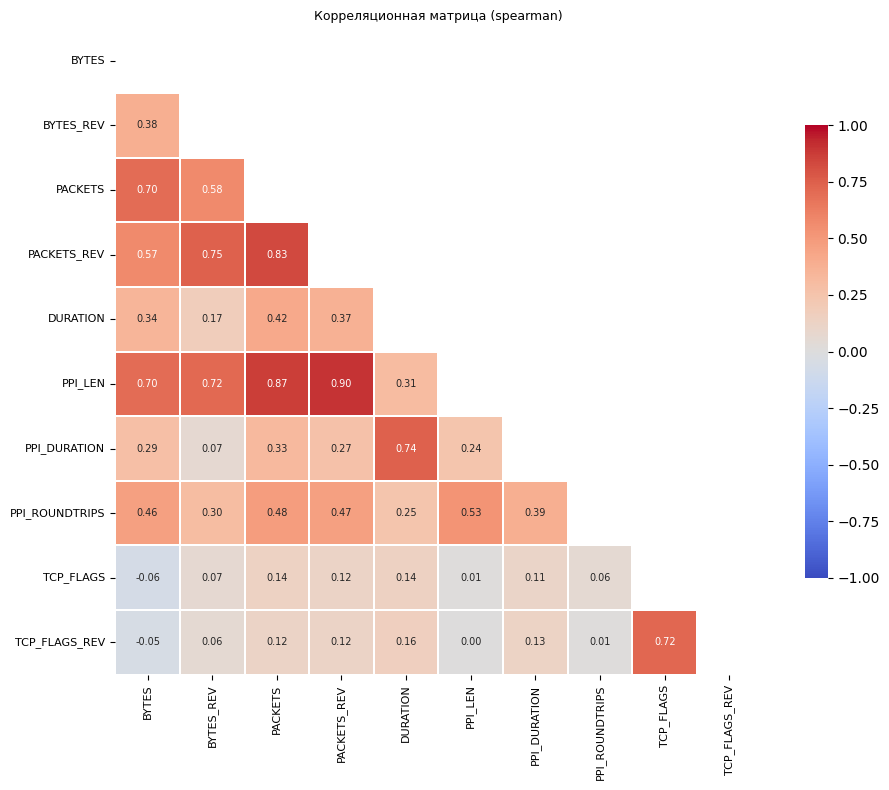

Сильно коррелирующие пары:
      feature_1    feature_2  corr
2  PACKETS_REV      PPI_LEN  0.90
1      PACKETS      PPI_LEN  0.87
0      PACKETS  PACKETS_REV  0.83
Рекомендуется исключить: ['PACKETS_REV', 'PPI_LEN']


In [6]:
# iskl = ['PPI_LEN', 'FLAG_ECE', 'FLAG_URG_REV', 'FLAG_URG', 'FLAG_ACK', 'FLAG_PSH', 'FLAG_FIN_REV']
iskl = ['FLAG_CWR', 'FLAG_CWR_REV', 'FLAG_ECE', 'FLAG_ECE_REV', 'FLAG_URG', 'FLAG_URG_REV', 'FLAG_ACK', 'FLAG_ACK_REV', 'FLAG_PSH', 'FLAG_PSH_REV', 'FLAG_RST', 'FLAG_RST_REV', 'FLAG_SYN', 'FLAG_SYN_REV', 'FLAG_FIN', 'FLAG_FIN_REV']
# iskl = []
numeric_cols = [c for c in df.columns if c not in iskl]


res = correlation_matrix(df, numeric_cols, threshold=0.8, method="spearman")
print("Сильно коррелирующие пары:\n", res["high_corr_pairs"])
print("Рекомендуется исключить:", res["to_drop"])

In [7]:
df = df.drop(iskl, axis=1)
df.head()

,BYTES,BYTES_REV,PACKETS,PACKETS_REV,DURATION,PPI_LEN,PPI_DURATION,PPI_ROUNDTRIPS,APP,TCP_FLAGS,TCP_FLAGS_REV
0,793,715,5,6,0.008550,5,0.004,2,facebook-web,26,26
1,2386,4689,11,9,0.098527,8,0.082,2,bitdefender-nimbus,27,27
2,1136,12840,9,16,0.112252,15,0.079,2,google-www,27,27
3,3430,540,7,8,0.442061,7,0.228,2,dropbox,26,26
4,1170,3548,12,9,0.159959,11,0.090,3,microsoft-update,27,27


In [12]:
df.APP.value_counts().reset_index()

,APP,count
0,microsoft-update,5826
1,microsoft-diagnostic,4669
2,microsoft-settings,4001
3,outlook,3100
4,tiktok,2900
...,...,...
178,ctu-kosapi,10
179,adobe-search,7
180,redmine,7
181,katastr-nahlizeni,4


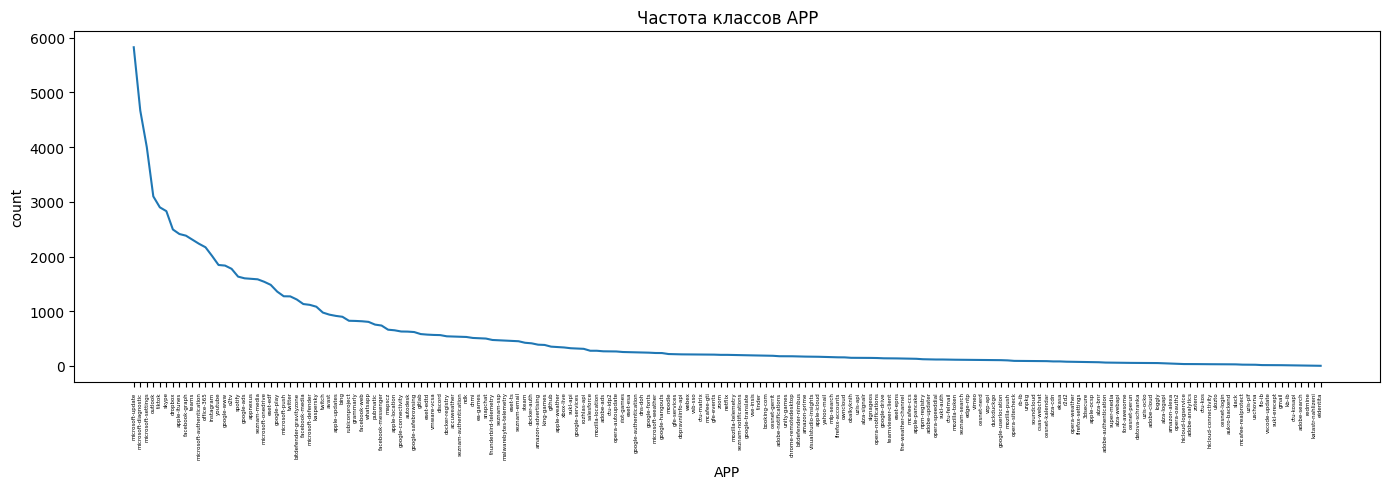

In [13]:
import matplotlib.pyplot as plt

counts = df["APP"].value_counts().reset_index()
counts.columns = ["APP", "count"]        # имена колонок после reset_index

plt.figure(figsize=(14, 5))
plt.plot(counts["APP"], counts["count"])
plt.xticks(rotation=90, fontsize=4)      # 187 подписей — иначе не читается
plt.xlabel("APP")
plt.ylabel("count")
plt.title("Частота классов APP")
plt.tight_layout()
plt.show()

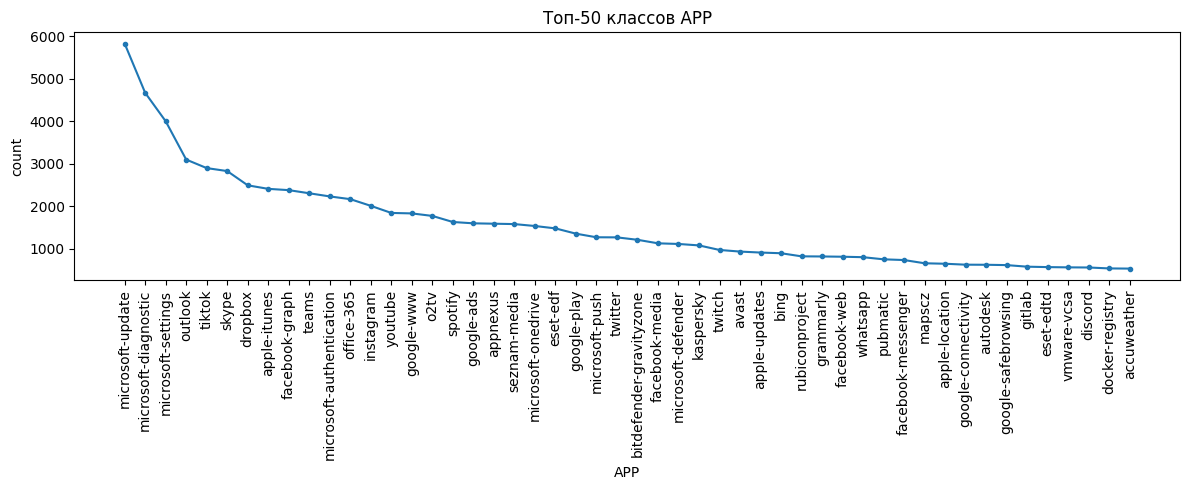

In [14]:
import matplotlib.pyplot as plt

counts = df["APP"].value_counts().reset_index()
counts.columns = ["APP", "count"]        # имена колонок после reset_index

# plt.figure(figsize=(14, 5))
# plt.plot(counts["APP"], counts["count"])
# plt.xticks(rotation=90, fontsize=4)      # 187 подписей — иначе не читается
# plt.xlabel("APP")
# plt.ylabel("count")
# plt.title("Частота классов APP")
# plt.tight_layout()
# plt.show()

top_n = 50
top = counts.head(top_n)

plt.figure(figsize=(12, 5))
plt.plot(top["APP"], top["count"], marker="o", markersize=3)
plt.xticks(rotation=90)
plt.xlabel("APP")
plt.ylabel("count")
plt.title(f"Топ-{top_n} классов APP")
plt.tight_layout()
plt.show()

In [15]:
lst = list(top.APP)
len(lst)

50

In [16]:
df_cut = df[df["APP"].isin(lst)].reset_index(drop=True)
df_cut["APP"] = df_cut["APP"].cat.remove_unused_categories()
df_cut.shape

(77738, 11)

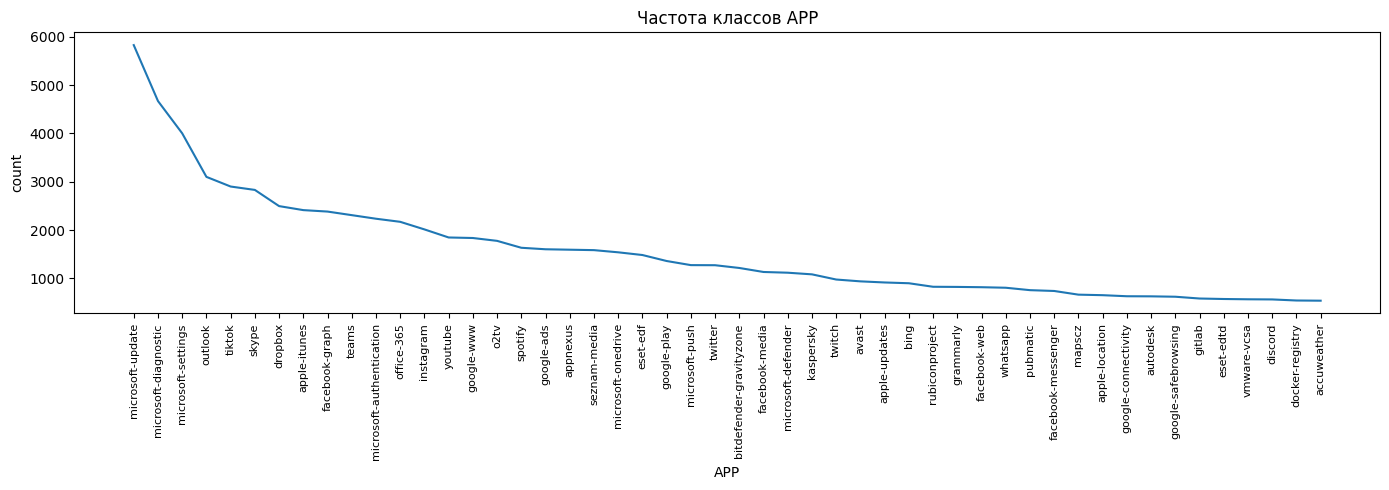

In [17]:
import matplotlib.pyplot as plt

counts = df_cut["APP"].value_counts().reset_index()
counts.columns = ["APP", "count"]        # имена колонок после reset_index

plt.figure(figsize=(14, 5))
plt.plot(counts["APP"], counts["count"])
plt.xticks(rotation=90, fontsize=8)      # 187 подписей — иначе не читается
plt.xlabel("APP")
plt.ylabel("count")
plt.title("Частота классов APP")
plt.tight_layout()
plt.show()

In [18]:
df_cut.APP.value_counts().reset_index().tail()

,APP,count
45,eset-edtd,573
46,vmware-vcsa,567
47,discord,564
48,docker-registry,542
49,accuweather,538


In [19]:
from sklearn.model_selection import train_test_split

X = df_cut.drop(columns=["APP"])
y = df_cut["APP"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y,
)
len(X_train), len(X_test)

(62190, 15548)

In [23]:
%load_ext cuml.accel

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics  import accuracy_score, f1_score, recall_score, precision_score

pipe_rf = make_pipeline(
    RandomForestClassifier(n_estimators=58,
                           max_depth=24,
                           random_state=1)
)
pipe_rf.fit(X_train, y_train)

y_pred = pipe_rf.predict(X_test)
print('Accuracy(test):  %.2f' % accuracy_score(y_test, y_pred))
print('Recall(test):    %.2f' % recall_score(y_test, y_pred, average='weighted'))
print('Precision(test): %.2f' % precision_score(y_test, y_pred, average='weighted'))
print('F1(test):        %.2f' % f1_score(y_test, y_pred, average='weighted'))
print_aligned_dict(pipe_rf.get_params())

/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [06:35:27] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.2
  warnings.warn(py_str(msg))


Accuracy(test):  0.84
Recall(test):    0.84
Precision(test): 0.84
F1(test):        0.84
                                          memory: null
                                           steps: [('randomforestclassifier', RandomForestClassifier(max_depth=24, n_estimators=58, random_state=1))]
                                 transform_input: null
                                         verbose: false
                          randomforestclassifier: RandomForestClassifier(max_depth=24, n_estimators=58, random_state=1)
               randomforestclassifier__bootstrap: true
               randomforestclassifier__ccp_alpha: 0.00
            randomforestclassifier__class_weight: null
               randomforestclassifier__criterion: "gini"
               randomforestclassifier__max_depth: 24
            randomforestclassifier__max_features: "sqrt"
          randomforestclassifier__max_leaf_nodes: null
             randomforestclassifier__max_samples: null
   randomforestclassifier__min_imp

In [26]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="treelite")

In [27]:
# подбор параметров полным перебором
# простой перебо по сетке
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score
import numpy as np
from sklearn.model_selection import GridSearchCV

param_grid = {
    'randomforestclassifier__max_depth': range(20, 30),
    'randomforestclassifier__n_estimators': range(55, 65)
}

pipe_rf = make_pipeline(
    RandomForestClassifier(random_state=1)
)
gs = GridSearchCV(estimator=pipe_rf,
                  param_grid=param_grid,
                  scoring='accuracy',
                  refit=True,
                  cv=2,                       # !!!
                  n_jobs=1,
                  verbose=3)
gs = gs.fit(X_train, y_train)
print_aligned_dict(gs.best_params_)

y_pred = gs.best_estimator_.predict(X_test)
# Вычисляем все метрики
accuracy  = accuracy_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred, average='weighted')
recall    = recall_score(y_test, y_pred, average='weighted')
precision = precision_score(y_test, y_pred, average='weighted')
# Выводим результаты
print('')
print('Accuracy(test):  %.2f' % accuracy)
print('Recall(test):    %.2f' % recall)
print('Precision(test): %.2f' % precision)
print('F1(test)         %.2f' % f1)

Fitting 2 folds for each of 100 candidates, totalling 200 fits
[CV 1/2] END randomforestclassifier__max_depth=20, randomforestclassifier__n_estimators=55;, score=0.813 total time=   6.3s
[CV 2/2] END randomforestclassifier__max_depth=20, randomforestclassifier__n_estimators=55;, score=0.811 total time=   4.4s
[CV 1/2] END randomforestclassifier__max_depth=20, randomforestclassifier__n_estimators=56;, score=0.813 total time=   4.6s
[CV 2/2] END randomforestclassifier__max_depth=20, randomforestclassifier__n_estimators=56;, score=0.811 total time=   4.0s
[CV 1/2] END randomforestclassifier__max_depth=20, randomforestclassifier__n_estimators=57;, score=0.813 total time=   4.2s
[CV 2/2] END randomforestclassifier__max_depth=20, randomforestclassifier__n_estimators=57;, score=0.811 total time=   4.6s
[CV 1/2] END randomforestclassifier__max_depth=20, randomforestclassifier__n_estimators=58;, score=0.813 total time=   4.8s
[CV 2/2] END randomforestclassifier__max_depth=20, randomforestclassi

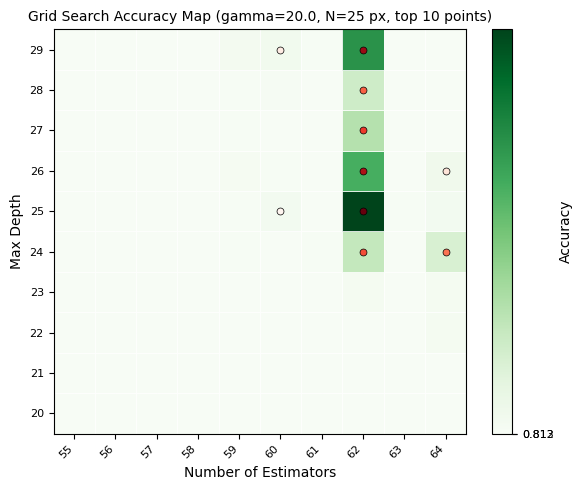

In [28]:
#  отображение результата перебора на тепловой карте
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle
from matplotlib.colors import PowerNorm

# Извлекаем результаты для карты
results = gs.cv_results_
max_depth_values = param_grid['randomforestclassifier__max_depth']
n_estimators_values = param_grid['randomforestclassifier__n_estimators']

# Создаем матрицу точности
accuracy_matrix = np.zeros((len(max_depth_values), len(n_estimators_values)))

for i, max_depth in enumerate(max_depth_values):
    for j, n_estimators in enumerate(n_estimators_values):
        idx = np.where((results['param_randomforestclassifier__max_depth'].data == max_depth) &
                       (results['param_randomforestclassifier__n_estimators'].data == n_estimators))[0][0]
        accuracy_matrix[i, j] = results['mean_test_score'][idx]

# Параметры отображения
N = 25  # размер квадратика в пикселях (чем больше, тем крупнее квадраты)
gamma = 20.0  # чем больше gamma, тем сильнее подавляются низкие значения (осветляются)
MAX_N = 10  # количество отображаемых точек максимума
MAX_S = 1  # размер точек максимума в пикселях

# Определяем размер квадрата в координатах графика
# Чем больше N, тем больше места занимает каждый квадрат
square_size = 0.5 + (N / 50)  # при N=20 -> size=0.9, при N=50 -> size=1.5

# Нормализуем значения точности для степенной шкалы (подавление низких значений)
vmin = np.min(accuracy_matrix)
vmax = np.max(accuracy_matrix)
norm = PowerNorm(gamma=gamma, vmin=vmin, vmax=vmax)

# Создаем график
fig, ax = plt.subplots(figsize=(6, 5))

# Рисуем квадратики
for i, depth in enumerate(max_depth_values):
    for j, estimators in enumerate(n_estimators_values):
        acc_value = accuracy_matrix[i, j]
        # Нормализуем значение для цветовой карты
        color_idx = norm(acc_value)
        color = plt.cm.Greens(color_idx)

        # Рисуем квадрат размером square_size
        rect = Rectangle((estimators - square_size/2, depth - square_size/2),
                         square_size, square_size,
                         facecolor=color, edgecolor='white', linewidth=0.5)
        ax.add_patch(rect)

# Находим TOP MAX_N точек максимума
all_accuracies = accuracy_matrix.flatten()
top_indices = np.argsort(all_accuracies)[-MAX_N:][::-1]
top_positions = [np.unravel_index(idx, accuracy_matrix.shape) for idx in top_indices]

# Нормализуем значения точности для цветовой шкалы (от темно-красного к светлому)
top_accuracies = [accuracy_matrix[i, j] for i, j in top_positions]
min_top_acc = min(top_accuracies)
max_top_acc = max(top_accuracies)

# Отмечаем TOP MAX_N точек с градиентом от темно-красного к светлому
for idx, (i, j) in enumerate(top_positions):
    acc_value = accuracy_matrix[i, j]
    depth_val = max_depth_values[i]
    estimators_val = n_estimators_values[j]

    # Нормализуем значение для цветовой карты красных оттенков
    if max_top_acc - min_top_acc > 0:
        color_norm = (acc_value - min_top_acc) / (max_top_acc - min_top_acc)
    else:
        color_norm = 0.5

    # Цвет от темно-красного (0) до светло-красного/розового (1)
    color = plt.cm.Reds(color_norm)

    # Размер точки максимума тоже зависит от N
    point_size = MAX_S * N
    ax.scatter(estimators_val, depth_val,
              s=point_size, marker='o', color=color,
              edgecolors='black', linewidth=0.5, zorder=5)

# Настройка осей
ax.set_xlabel('Number of Estimators', fontsize=10)
ax.set_ylabel('Max Depth', fontsize=10)
ax.set_title(f'Grid Search Accuracy Map (gamma={gamma}, N={N} px, top {MAX_N} points)', fontsize=10)

# Устанавливаем границы осей с учетом размера квадратов
margin = square_size / 2
ax.set_xlim(min(n_estimators_values) - margin, max(n_estimators_values) + margin)
ax.set_ylim(min(max_depth_values) - margin, max(max_depth_values) + margin)

# Настройка меток на осях
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=8, integer=True))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6, integer=True))

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
plt.setp(ax.get_yticklabels(), fontsize=8)

# Добавляем цветовую легенду с степенной нормализацией
sm = plt.cm.ScalarMappable(cmap='Greens', norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Accuracy', fontsize=10)
cbar.ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=2))
cbar.ax.tick_params(labelsize=8)

# Настройка сетки
ax.set_xticks(n_estimators_values)
ax.set_yticks(max_depth_values)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5, color='gray')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier

# Определяем несколько метрик
scoring = {
    'accuracy'  : 'accuracy',
    'f1'        : make_scorer(f1_score, average='weighted'),
    'recall'    : make_scorer(recall_score, average='weighted'),
    'precision' : make_scorer(precision_score, average='weighted')
}

pipe_rf = make_pipeline(
    RandomForestClassifier(n_estimators=62, # 10 20 40 20 18 15 42
                           max_depth=25,    # 12  9 14 22 14 14 14
                           random_state=1)  # 88 87 89 90 89 88 90
)
scores = cross_validate(estimator=pipe_rf,
                        X=X_train,
                        y=y_train,
                        cv=2,
                        scoring=scoring,
                        n_jobs=-1)

# Выводим результаты
print('')
for metric_name in scores.keys():
    if metric_name.startswith('test_'):  # только метрики
        metric_scores = scores[metric_name]
        print(f'{metric_name[5:]:<10}(test): {np.mean(metric_scores):.2f} +/- {np.std(metric_scores):.3f}')


accuracy  (test): 0.82 +/- 0.000
f1        (test): 0.81 +/- 0.000
recall    (test): 0.82 +/- 0.000
precision (test): 0.81 +/- 0.000


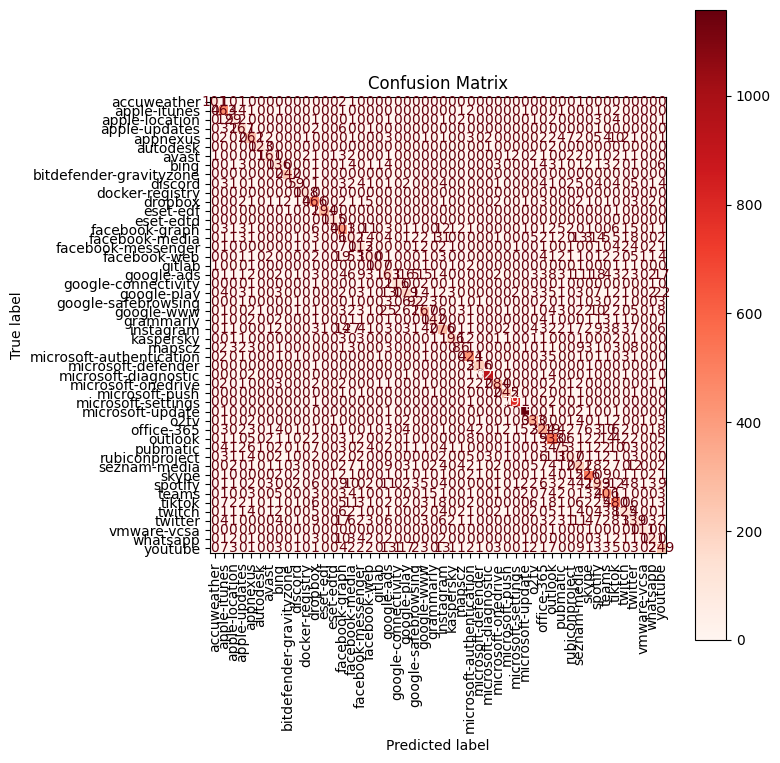

In [22]:
# полная матрица ошибок
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# 1. Явно обучаем пайплайн на тренировочных данных
pipe_rf.fit(X_train, y_train)
# Предсказания
y_pred = pipe_rf.predict(X_test)

# Построение матрицы
cm = confusion_matrix(y_test, y_pred, labels=pipe_rf.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipe_rf.classes_)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap='Reds', ax=ax, xticks_rotation='vertical')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

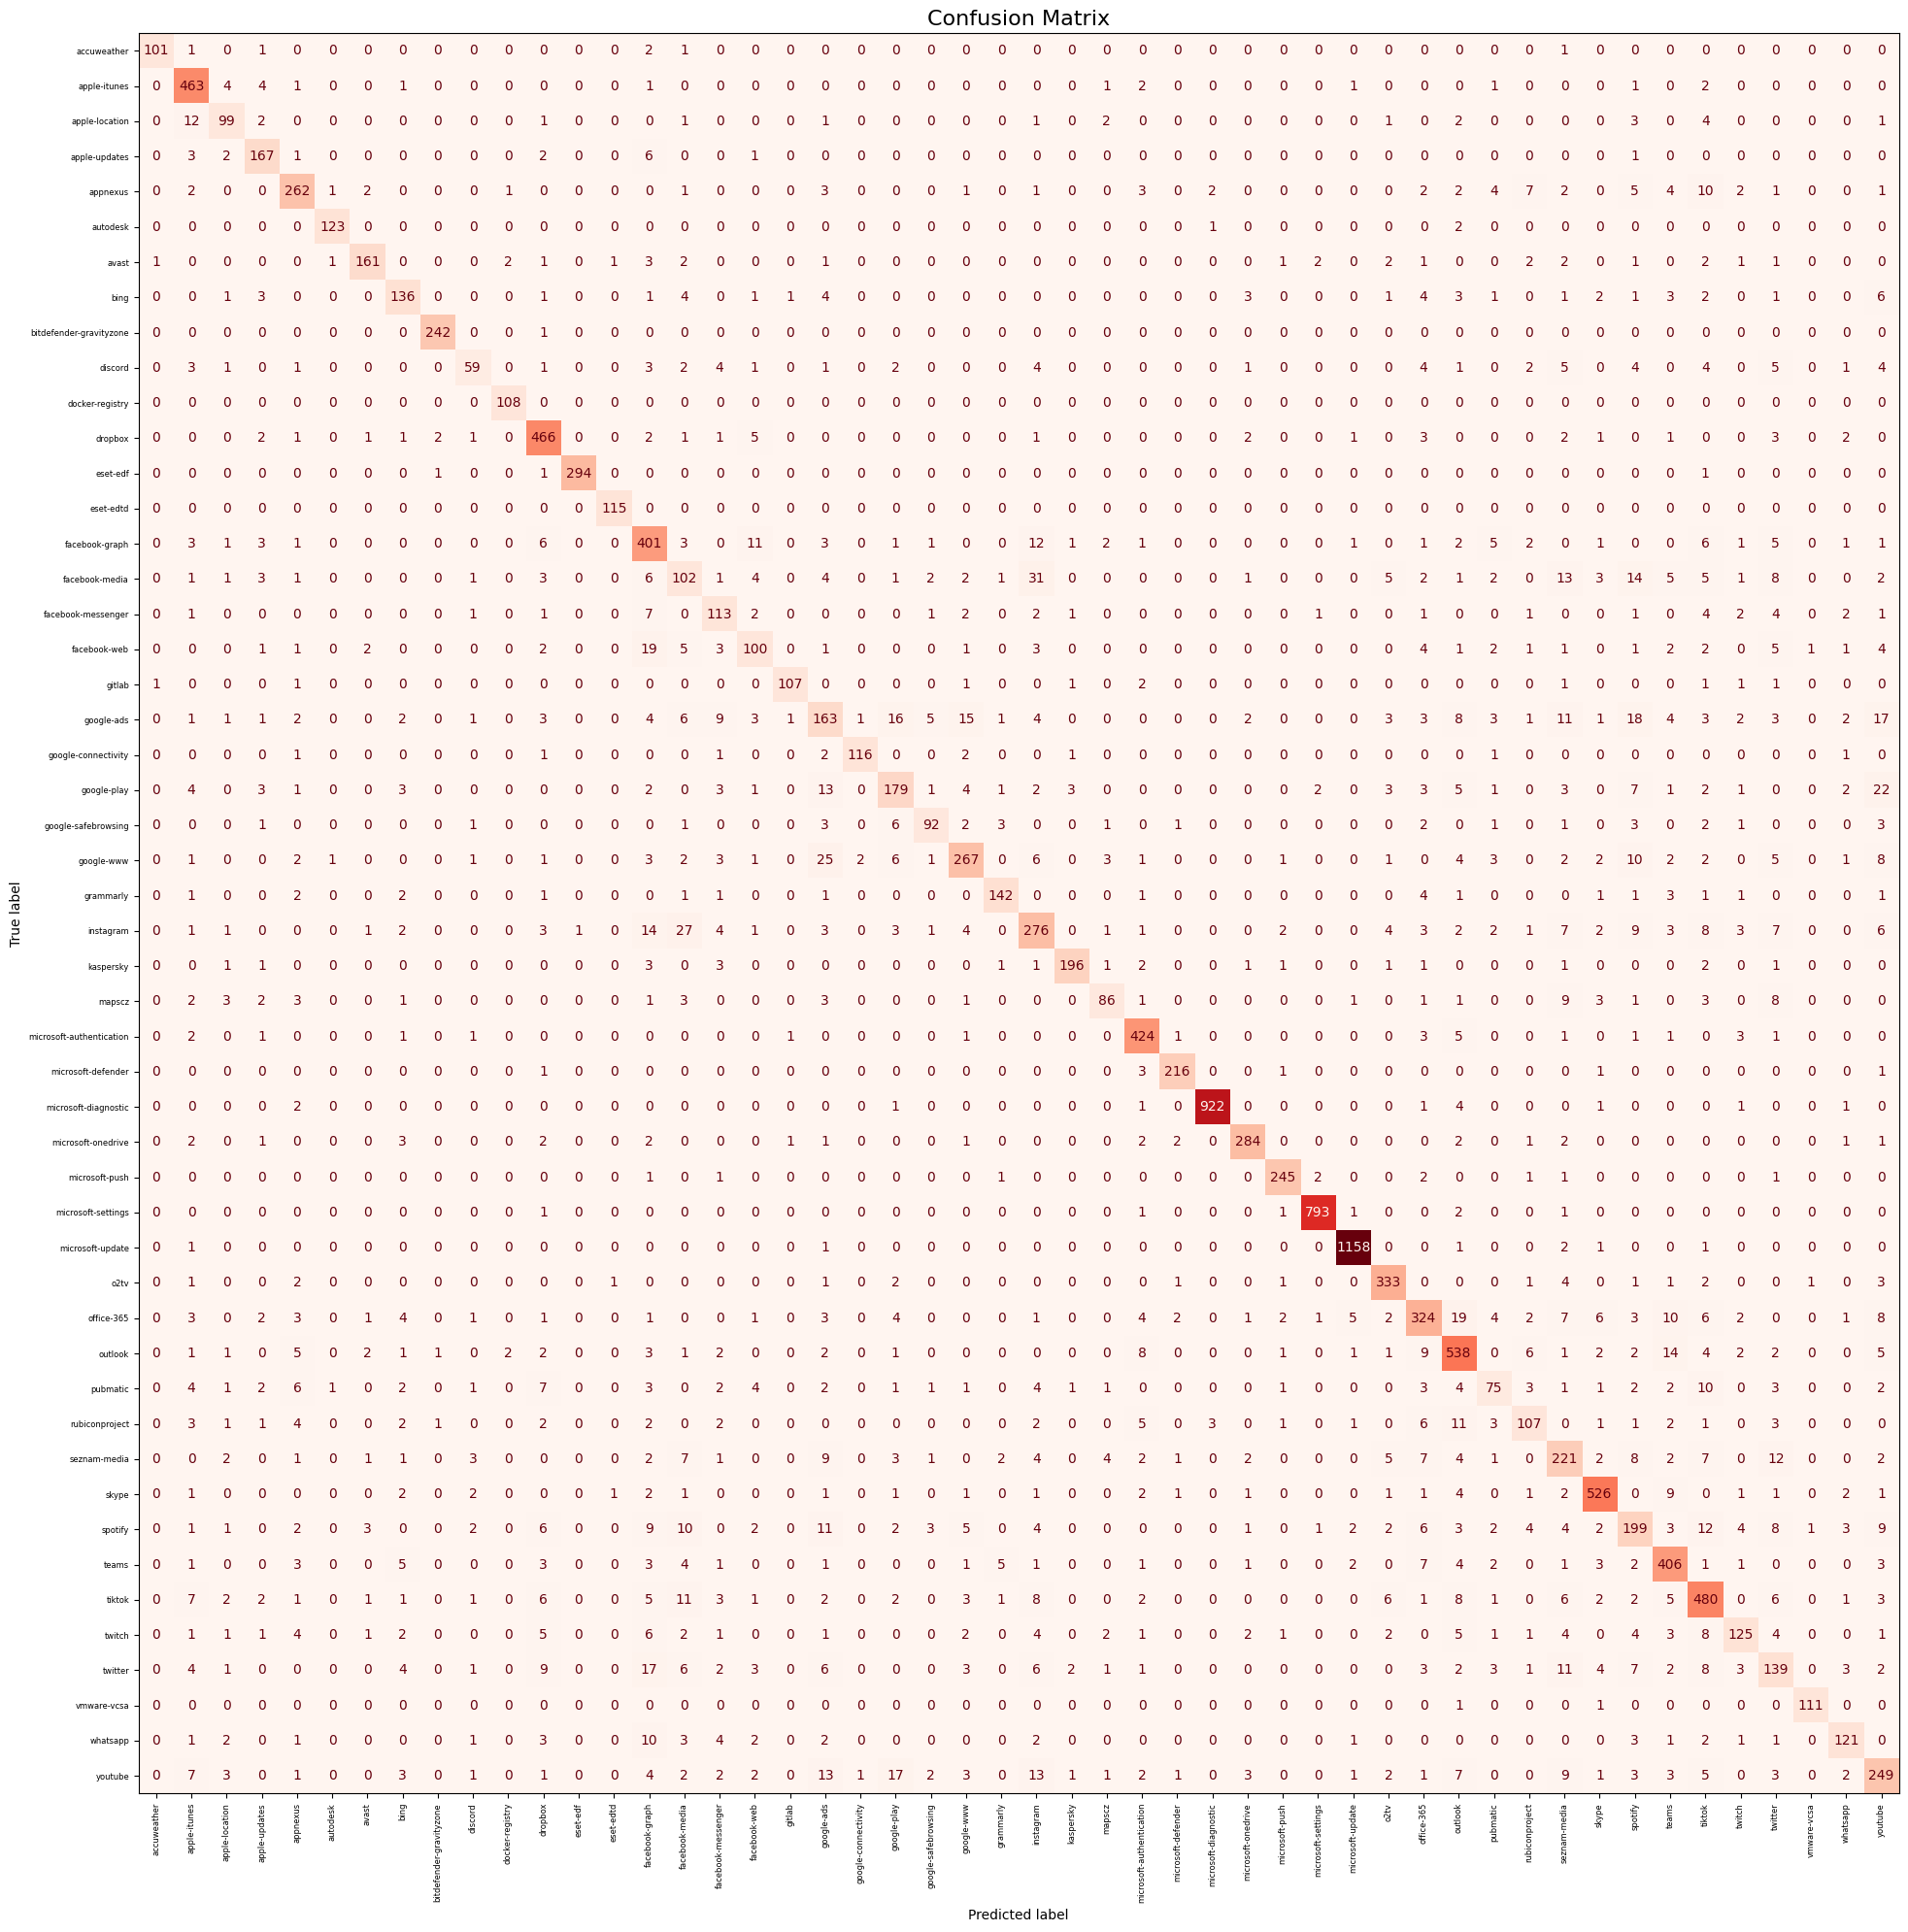

In [23]:
# полная матрица ошибок
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# 1. Явно обучаем пайплайн на тренировочных данных
pipe_rf.fit(X_train, y_train)
# Предсказания
y_pred = pipe_rf.predict(X_test)

# Построение матрицы
cm = confusion_matrix(y_test, y_pred, labels=pipe_rf.classes_)

# Увеличиваем холст (например, 20x20 дюймов)
fig, ax = plt.subplots(figsize=(20, 20))

# Создаем объект дисплея, но пока не рисуем
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipe_rf.classes_)

# Рисуем.
# ВАЖНО: передаем values_format='d' (целые числа) и добавляем colorbar=False,
# чтобы шкала не перекрывала и без того тесные подписи.
disp.plot(cmap='Reds', ax=ax, xticks_rotation='vertical', values_format='d', colorbar=False)

# Уменьшаем размер шрифта для подписей осей (191 класс — это очень много)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=6)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=6)

plt.title('Confusion Matrix', fontsize=16)
plt.tight_layout()
plt.show()

In [24]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=pipe_rf.classes_))

                          precision    recall  f1-score   support

             accuweather       0.98      0.94      0.96       107
            apple-itunes       0.86      0.96      0.91       482
          apple-location       0.76      0.76      0.76       130
           apple-updates       0.82      0.91      0.86       183
                appnexus       0.83      0.82      0.83       319
                autodesk       0.97      0.98      0.97       126
                   avast       0.91      0.86      0.88       188
                    bing       0.76      0.76      0.76       180
 bitdefender-gravityzone       0.98      1.00      0.99       243
                 discord       0.75      0.52      0.61       113
         docker-registry       0.96      1.00      0.98       108
                 dropbox       0.86      0.93      0.89       499
                eset-edf       1.00      0.99      0.99       297
               eset-edtd       0.97      1.00      0.99       115
         

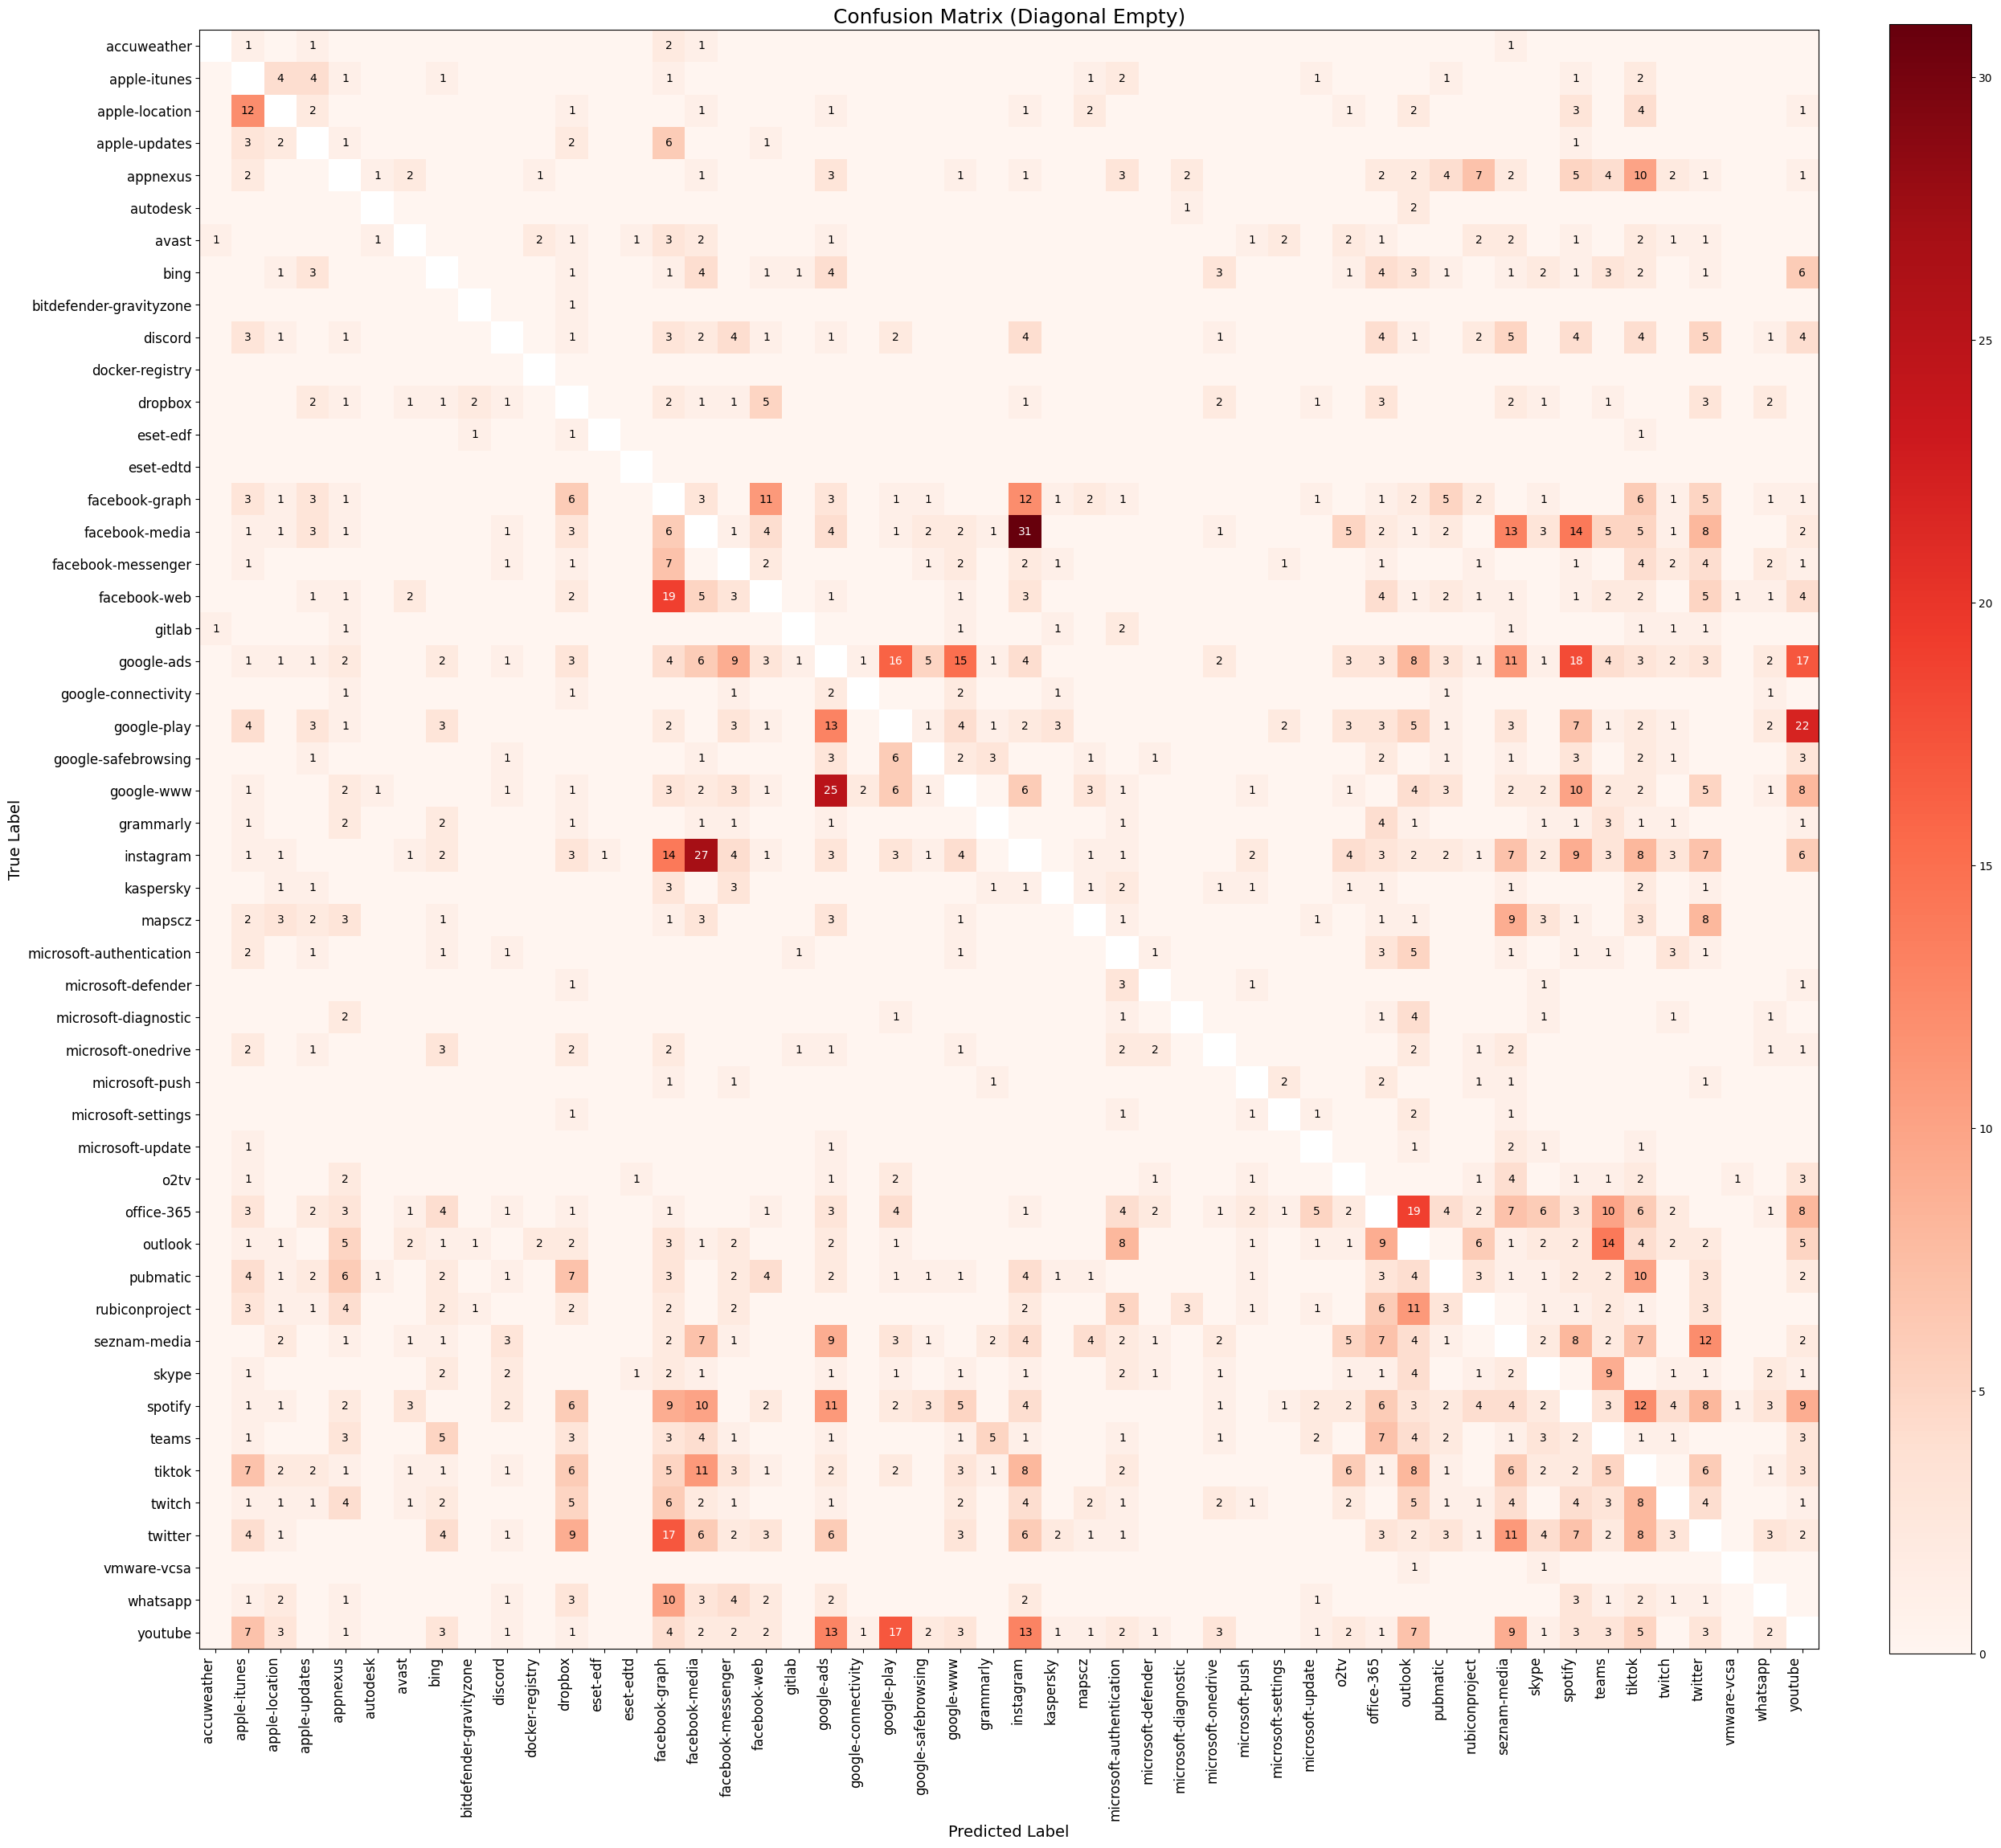

In [31]:
# матрица ошибок без диагональных элементов
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Предсказания
y_pred = pipe_rf.predict(X_test)

# Построение матрицы
cm = confusion_matrix(y_test, y_pred, labels=pipe_rf.classes_)

# Конвертируем в float (чтобы можно было использовать NaN)
cm = cm.astype(float)

# Очищаем диагональные элементы (делаем их NaN)
np.fill_diagonal(cm, np.nan)

# Создаем ОЧЕНЬ БОЛЬШУЮ фигуру
fig, ax = plt.subplots(figsize=(25, 25))

# Отображаем матрицу
im = ax.imshow(cm, cmap='Reds', interpolation='none')

# Цветовая шкала
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Подписи осей
ax.set_xticks(np.arange(len(pipe_rf.classes_)))
ax.set_yticks(np.arange(len(pipe_rf.classes_)))

# Уменьшаем шрифт подписей
ax.set_xticklabels(pipe_rf.classes_, rotation=90, ha='right', fontsize=12)
ax.set_yticklabels(pipe_rf.classes_, fontsize=12)

# Добавляем значения в ячейки (кроме диагонали)
# ВАЖНО: рисуем цифры только там, где ошибка > 0, иначе matplotlib зависнет
max_error = np.nanmax(cm)
for i in range(len(cm)):
    for j in range(len(cm)):
        if i != j and not np.isnan(cm[i, j]) and cm[i, j] > 0:
            # Определяем цвет текста (белый на темном фоне, черный на светлом)
            color = "white" if cm[i, j] > max_error / 2 else "black"
            text = ax.text(j, i, int(cm[i, j]),
                          ha="center", va="center",
                          color=color, fontsize=10) # 5pt — чтобы влезло в микро-ячейки

ax.set_xlabel('Predicted Label', fontsize=14)
ax.set_ylabel('True Label', fontsize=14)
ax.set_title('Confusion Matrix (Diagonal Empty)', fontsize=18)

plt.tight_layout()
plt.show()

 1) PACKETS                        0.219781
 2) BYTES_REV                      0.152904
 3) PPI_ROUNDTRIPS                 0.115981
 4) PPI_LEN                        0.109614
 5) DURATION                       0.100978
 6) PPI_DURATION                   0.088643
 7) PACKETS_REV                    0.073787
 8) APP                            0.057952
 9) TCP_FLAGS                      0.043043
10) TCP_FLAGS_REV                  0.037317


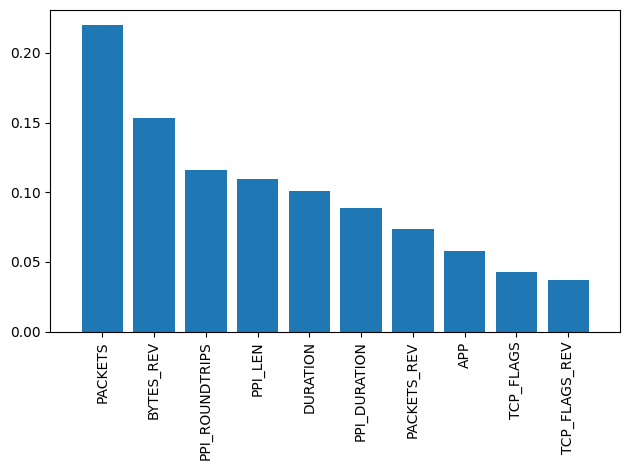

In [32]:
# построить диаграмму занчимости признаков
importances = pipe_rf.named_steps['randomforestclassifier'].feature_importances_
indices = np.argsort(importances)[::-1]
feat_labels = df.columns[1:]

for f in range(X_train.shape[1]):
    print("%2d) %-*s %f" % (
        f + 1,
        30,
        feat_labels[indices[f]],
        importances[indices[f]])
    )

# plt.t('Feature Importance')
plt.bar(range(X_train.shape[1]),
        importances[indices],
        align='center')

plt.xticks(range(X_train.shape[1]), feat_labels[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
#plt.savefig('images/04_09.png', dpi=300)
plt.show()